# Modula: AI-assisted configuration of modular smartphones

Aditi R Sankpal, Diya S Ellur, Mahiyu Dasgupta, Nidhi K, Rajat L Harihar

A person describes how they use a phone. Claude turns that into a nine-axis need vector, and a constrained search picks the modules and places them on the frame. Claude never chooses hardware: Python enforces budget, space, dependencies and placement.

**To run it:** choose *Runtime > Run all*. Nothing needs installing and no key is needed.

**What runs here:** the search, placement, evaluation and tests all run live. Claude itself doesn't, because the Claude command line isn't available in Colab. Examples use recorded Claude replies, and typed requests use keyword matching. Each result says which one it used.

Sections: 1 Catalogue, 2 Search, 3 Prompts, 4 Recorded data, 5 Keyword baseline, 6 Claude call, 7 Figures, 8 Results, 9 Tests, 10 Worked examples, 11 Try it.

In [1]:
import json
import logging
import math
import shutil
import subprocess
import sys
import unittest
from base64 import b64encode
from dataclasses import dataclass, field
from functools import lru_cache
from html import escape
from io import BytesIO
from itertools import product
from statistics import mean

import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import HTML, display
from matplotlib.figure import Figure
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle

# Colab doesn't have the Windows fonts named below, so matplotlib falls back to DejaVu Sans.
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)


## 1. Module catalogue

23 modules on a 2 × 6 frame. Prices, masses and power figures are illustrative design assumptions, not measured hardware.

In [2]:
from dataclasses import dataclass, field

# The shared vector space. Module attributes, configurations and user needs
# are all expressed along these nine axes.
DIMS = ("camera", "performance", "battery", "audio", "storage",
        "connectivity", "durability", "sensing", "portability")

DIM_LABELS = {
    "camera": "Camera", "performance": "Performance", "battery": "Battery life",
    "audio": "Audio", "storage": "Storage", "connectivity": "Connectivity",
    "durability": "Durability", "sensing": "Sensing", "portability": "Portability",
}

# The frame: 2 columns by 6 rows of module cells, plus the display and shell.
GRID_COLS = 2
GRID_ROWS = 6

BASE_PRICE = 9000
BASE_MASS = 110
BASE_DRAW = 1.0
BASE_ATTRS = {"audio": 0.15, "storage": 0.15, "connectivity": 0.3, "durability": 0.2}


@dataclass(frozen=True)
class Module:
    id: str
    cat: str
    name: str
    short: str
    w: int  # width in grid cells
    h: int  # height in grid cells
    price: int
    mass: int
    draw: float  # average watts in mixed use
    attrs: dict = field(default_factory=dict, hash=False)
    wh: float = 0.0  # battery capacity
    requires: tuple = ()


# (id, label, required). Required categories must be present in every phone.
CATEGORIES = (
    ("compute", "Compute", True),
    ("battery", "Battery", True),
    ("camera", "Main camera", True),
    ("aux", "Second camera", False),
    ("audio", "Audio", False),
    ("storage", "Storage", False),
    ("net", "Connectivity", False),
    ("sensor", "Sensors", False),
    ("armour", "Protection", False),
    ("cooling", "Cooling", False),
)
CATEGORY_LABELS = {c[0]: c[1] for c in CATEGORIES}

MODULES = (
    Module("c-eff", "compute", "Efficiency SoC", "Efficiency SoC", 2, 1, 6000, 18, 0.7, {"performance": 0.45}),
    Module("c-bal", "compute", "Balanced SoC", "Balanced SoC", 2, 1, 11000, 20, 1.1, {"performance": 0.68}),
    Module("c-pro", "compute", "Flagship SoC", "Flagship SoC", 2, 1, 22000, 22, 1.6, {"performance": 0.88}),
    Module("c-game", "compute", "Overclocked gaming SoC", "Gaming SoC", 2, 1, 27000, 28, 2.1, {"performance": 0.97},
           requires=("cool-vc",)),

    Module("b-3000", "battery", "3,000 mAh pack", "3,000 mAh", 2, 1, 1800, 46, 0.0, {}, wh=11.6),
    Module("b-4500", "battery", "4,500 mAh pack", "4,500 mAh", 1, 3, 2500, 68, 0.0, {}, wh=17.4),
    Module("b-6000", "battery", "6,000 mAh pack", "6,000 mAh", 2, 2, 3400, 92, 0.0, {}, wh=23.2),
    Module("b-8000", "battery", "8,000 mAh pack", "8,000 mAh", 2, 3, 5000, 122, 0.0, {}, wh=31.0),

    Module("cam-50", "camera", "50 MP standard camera", "50 MP", 1, 1, 2500, 8, 0.1, {"camera": 0.45}),
    Module("cam-108", "camera", "108 MP wide camera", "108 MP", 2, 1, 6500, 14, 0.15, {"camera": 0.7}),
    Module("cam-1in", "camera", "1-inch pro sensor", "1-inch sensor", 2, 2, 14000, 30, 0.25, {"camera": 0.92}),

    Module("aux-uw", "aux", "Ultrawide + macro lens", "Ultrawide", 1, 1, 3000, 6, 0.05, {"camera": 0.2}),
    Module("aux-tele", "aux", "5x periscope telephoto", "5x tele", 2, 1, 7000, 14, 0.08, {"camera": 0.35}),

    Module("aud-st", "audio", "Stereo speaker module", "Stereo", 1, 1, 2000, 8, 0.1, {"audio": 0.5}),
    Module("aud-hifi", "audio", "Hi-Fi DAC + speakers", "Hi-Fi DAC", 2, 1, 6500, 12, 0.15, {"audio": 0.88}),

    Module("st-512", "storage", "512 GB storage", "512 GB", 1, 1, 3000, 3, 0.02, {"storage": 0.65}),
    Module("st-2tb", "storage", "2 TB storage", "2 TB", 1, 1, 9500, 5, 0.05, {"storage": 0.95}),

    Module("net-sat", "net", "Satellite + long-range radio", "Satellite", 1, 1, 5500, 7, 0.1, {"connectivity": 0.65}),
    Module("net-mm", "net", "mmWave 5G + Wi-Fi 7", "mmWave", 1, 1, 5000, 6, 0.2, {"connectivity": 0.72}),

    Module("sen-health", "sensor", "ECG, SpO2 + temperature", "Health", 1, 1, 4500, 5, 0.05, {"sensing": 0.72}),
    Module("sen-env", "sensor", "Thermal + air quality", "Thermal + air", 1, 1, 6000, 6, 0.05, {"sensing": 0.65}),

    Module("arm-rug", "armour", "Rugged armour spine", "Armour", 2, 1, 3500, 45, 0.0, {"durability": 0.75}),

    Module("cool-vc", "cooling", "Vapour chamber", "Cooling", 1, 1, 2500, 10, 0.0, {"performance": 0.08}),
)
MODULE_BY_ID = {m.id: m for m in MODULES}

# Pairwise relationships between modules: effects a per-module vector can't express.
# (module a, module b, axis, change)
INTERACTIONS = (
    ("c-pro", "cool-vc", "performance", 0.05),    # cooling sustains flagship clocks
    ("c-pro", "cam-1in", "camera", 0.04),         # flagship ISP suits a 1-inch sensor
    ("c-game", "cam-1in", "camera", 0.04),
    ("c-eff", "cam-1in", "camera", -0.12),        # efficiency ISP bottlenecks it
    ("c-eff", "aud-hifi", "audio", -0.05),        # limits hi-res decoding
)

PLACEMENT_RULES = {
    "camera": "Top of the frame, clear of the grip",
    "aux": "Beside the main camera",
    "audio": "Bottom edge, facing out",
    "net": "Top or bottom edge, the antenna window",
    "sensor": "Mid-frame, under the index finger",
    "compute": "Away from the battery",
    "cooling": "Touching the SoC",
    "battery": "Near the centre, for balance",
}


## 2. Vector search and placement

The need and every candidate phone sit in the same nine-axis space. Hard limits filter first: frame space, budget, dependencies and required modules. The rest are ranked by `0.5 × cosine + 0.5 × attainment − 0.2 × price ÷ ₹90,000`, then a depth-first search places the modules using heat, antenna, grip and balance costs.

In [3]:
import math
from dataclasses import dataclass
from functools import lru_cache
from itertools import product

import numpy as np


# Normalisation anchors for the two axes that come from physics, not attributes.
FULL_ENDURANCE_HOURS = 16
MASS_LIGHTEST = 150
MASS_HEAVIEST = 330

# Score weights. ALPHA balances direction (cosine) against strength (attainment).
ALPHA = 0.5
COST_PENALTY = 0.20
MAX_PRICE = 90000

PLACEMENT_NODE_LIMIT = 40000


def clamp01(x):
    return max(0.0, min(1.0, x))


@dataclass(frozen=True)
class Config:
    vec: dict
    mass: float
    draw: float
    wh: float
    price: int
    hours: float


@dataclass(frozen=True)
class Placed:
    mod: object
    x: int
    y: int
    w: int
    h: int


@dataclass(frozen=True)
class Build:
    mods: tuple
    config: Config
    score: float
    cos: float
    attainment: float
    placed: tuple
    placement_cost: float


def config_vector(mods):
    """Turns a list of modules into one vector in the shared 9-D space.

    Attributes stack with diminishing returns (noisy-OR), then interactions apply.
    Battery and portability are derived from watt-hours, total draw and total mass,
    so a heavier pack or a hungrier SoC changes them automatically.
    """
    miss = {d: 1 - BASE_ATTRS.get(d, 0) for d in DIMS}
    mass, draw, wh, price = BASE_MASS, BASE_DRAW, 0.0, BASE_PRICE
    ids = set()
    for m in mods:
        ids.add(m.id)
        mass += m.mass
        draw += m.draw
        price += m.price
        wh += m.wh
        for d, value in m.attrs.items():
            miss[d] *= 1 - value

    vec = {d: 1 - miss[d] for d in DIMS}
    for a, b, dim, delta in INTERACTIONS:
        if a in ids and b in ids:
            vec[dim] = clamp01(vec[dim] + delta)

    # Square root: going from 4h to 8h matters far more than going from 12h to 16h.
    hours = wh / draw if draw > 0 else 0.0
    vec["battery"] = math.sqrt(clamp01(hours / FULL_ENDURANCE_HOURS))
    vec["portability"] = clamp01(1 - (mass - MASS_LIGHTEST) / (MASS_HEAVIEST - MASS_LIGHTEST))
    return Config(vec, mass, draw, wh, price, hours)


def cosine(a, b):
    dot = na = nb = 0.0
    for d in DIMS:
        x, y = a.get(d, 0), b.get(d, 0)
        dot += x * y
        na += x * x
        nb += y * y
    return dot / math.sqrt(na * nb) if na and nb else 0.0


def fit_score(need, config):
    """Cosine rewards the right shape of phone but ignores how strong it is, and a weak
    phone can match perfectly in direction. Attainment fixes that by measuring how much
    capability the phone delivers on the axes this user weighted. Needs are squared so
    that a top priority outweighs several minor ones.
    """
    weighted = total = 0.0
    for d in DIMS:
        n = need.get(d, 0) ** 2
        weighted += n * config.vec[d]
        total += n
    attainment = weighted / total if total else 0.0
    cos = cosine(need, config.vec)
    score = ALPHA * cos + (1 - ALPHA) * attainment - COST_PENALTY * (config.price / MAX_PRICE)
    return score, cos, attainment


def _all_combinations():
    """Every legal choice: one module per category, or none where the category is optional."""
    options = []
    for cat, _, required in CATEGORIES:
        mods = [m for m in MODULES if m.cat == cat]
        options.append(mods if required else [None, *mods])
    capacity = GRID_COLS * GRID_ROWS
    out = []
    for choice in product(*options):
        mods = tuple(m for m in choice if m)
        if sum(m.w * m.h for m in mods) <= capacity:
            out.append(mods)
    return out


class _SearchTable:
    """All configurations as NumPy arrays, so ranking 16,000 phones takes milliseconds."""

    def __init__(self):
        self.combos = _all_combinations()
        self.configs = [config_vector(mods) for mods in self.combos]
        self.vectors = np.array([[c.vec[d] for d in DIMS] for c in self.configs])
        self.prices = np.array([c.price for c in self.configs], dtype=float)
        self.squared_norms = (self.vectors ** 2).sum(axis=1)
        index = {m.id: i for i, m in enumerate(MODULES)}
        self.module_index = index
        self.has = np.zeros((len(self.combos), len(MODULES)), dtype=bool)
        for row, mods in enumerate(self.combos):
            for m in mods:
                self.has[row, index[m.id]] = True
        self.deps_ok = np.array([_requirements_met(mods) for mods in self.combos])


def _requirements_met(mods):
    ids = {m.id for m in mods}
    return all(r in ids for m in mods for r in m.requires)


@lru_cache(maxsize=1)
def _table():
    return _SearchTable()


def possible_combinations():
    total = 1
    for cat, _, required in CATEGORIES:
        count = sum(m.cat == cat for m in MODULES)
        total *= count if required else count + 1
    return total


# ---- Placement: choose where each module sits on the 2 x 6 frame ----

def _within_camera_zone(mod, y, h):
    if mod.cat == "camera":
        return y + h <= 2
    if mod.cat == "aux":
        return y + h <= 3
    return True


def adjacent(a, b):
    overlaps_x = a.x < b.x + b.w and b.x < a.x + a.w
    overlaps_y = a.y < b.y + b.h and b.y < a.y + a.h
    return ((overlaps_x and (a.y + a.h == b.y or b.y + b.h == a.y)) or
            (overlaps_y and (a.x + a.w == b.x or b.x + b.w == a.x)))


def placement_cost(placed):
    """Soft ergonomic and thermal costs. Lower is better."""
    cost = 0.0
    mass_y = mass_total = 0.0
    by_cat = {}
    for p in placed:
        by_cat[p.mod.cat] = p
        mass_y += (p.y + p.h / 2) * p.mod.mass
        mass_total += p.mod.mass
        if p.mod.cat == "camera" and p.y != 0:
            cost += 4
        if p.mod.cat == "audio" and p.y + p.h != GRID_ROWS:
            cost += 3
        if p.mod.cat == "net" and p.y != 0 and p.y + p.h != GRID_ROWS:
            cost += 2
        if p.mod.cat == "sensor" and (p.y < 2 or p.y + p.h > 4):
            cost += 2

    compute, battery, cooling = by_cat.get("compute"), by_cat.get("battery"), by_cat.get("cooling")
    if compute and battery and adjacent(compute, battery):
        cost += 3
    if compute and cooling and not adjacent(compute, cooling):
        cost += 4
    if mass_total:
        cost += abs(mass_y / mass_total - GRID_ROWS / 2) * 0.5
    return cost


def _place_uncached(mods):
    """Depth-first search. Returns (placed, cost), or None when the modules can't physically fit."""
    def rank(m):
        return 0 if m.cat == "camera" else 1 if m.cat == "aux" else 2

    order = sorted(mods, key=lambda m: (rank(m), -m.w * m.h))
    grid = [[False] * GRID_COLS for _ in range(GRID_ROWS)]
    best, best_cost = None, math.inf
    nodes = 0

    def fits(x, y, w, h):
        if x + w > GRID_COLS or y + h > GRID_ROWS:
            return False
        return not any(grid[r][c] for r in range(y, y + h) for c in range(x, x + w))

    def mark(x, y, w, h, value):
        for r in range(y, y + h):
            for c in range(x, x + w):
                grid[r][c] = value

    def walk(i, placed):
        nonlocal best, best_cost, nodes
        nodes += 1
        if nodes > PLACEMENT_NODE_LIMIT:
            return
        if i == len(order):
            cost = placement_cost(placed)
            if cost < best_cost:
                best, best_cost = tuple(placed), cost
            return
        mod = order[i]
        shapes = [(mod.w, mod.h)] if mod.w == mod.h else [(mod.w, mod.h), (mod.h, mod.w)]
        for w, h in shapes:
            for y in range(GRID_ROWS):
                for x in range(GRID_COLS):
                    if not _within_camera_zone(mod, y, h) or not fits(x, y, w, h):
                        continue
                    mark(x, y, w, h, True)
                    placed.append(Placed(mod, x, y, w, h))
                    walk(i + 1, placed)
                    placed.pop()
                    mark(x, y, w, h, False)

    walk(0, [])
    return (best, best_cost) if best is not None else None


@lru_cache(maxsize=4096)
def _place_by_ids(ids):
    return _place_uncached([MODULE_BY_ID[i] for i in ids])


def place_modules(mods):
    return _place_by_ids(tuple(m.id for m in mods))


# ---- Recommendation ----

def _differs_enough(a, b):
    ids = {m.id for m in a}
    return sum(m.id not in ids for m in b) >= 2


def recommend(need, budget=None, must_have=(), top_n=3):
    """Hard constraints (cells, budget, dependencies, must-haves, placement) filter first.
    The survivors are ranked by fit score, and the best ones that can be physically placed
    are returned.
    """
    table = _table()
    n = np.array([need.get(d, 0) for d in DIMS], dtype=float)

    mask = table.deps_ok.copy()
    for module_id in must_have:
        if module_id in table.module_index:
            mask &= table.has[:, table.module_index[module_id]]
    if budget:
        mask &= table.prices <= budget

    feasible = np.flatnonzero(mask)
    stats = {"possible": possible_combinations(), "fit_frame": len(table.combos),
             "feasible": len(feasible), "placement_rejected": 0}
    if not len(feasible):
        return [], stats

    vectors = table.vectors[feasible]
    need_norm = float((n ** 2).sum())
    if need_norm:
        cos = (vectors @ n) / np.sqrt(table.squared_norms[feasible] * need_norm)
    else:
        cos = np.zeros(len(feasible))
    squared = n ** 2
    total = float(squared.sum())
    attainment = (vectors @ squared) / total if total else np.zeros(len(feasible))
    scores = ALPHA * cos + (1 - ALPHA) * attainment - COST_PENALTY * (table.prices[feasible] / MAX_PRICE)

    results = []
    for position in np.argsort(-scores, kind="stable"):
        if len(results) >= top_n:
            break
        row = feasible[position]
        mods = table.combos[row]
        if any(not _differs_enough(r.mods, mods) for r in results):
            continue
        placement = place_modules(mods)
        if placement is None:
            stats["placement_rejected"] += 1
            continue
        config = table.configs[row]
        score, cos_value, attainment_value = fit_score(need, config)
        results.append(Build(mods, config, score, cos_value, attainment_value, placement[0], placement[1]))
    return results, stats


def cheapest_possible():
    """The cheapest legal phone, used to explain an impossible budget."""
    return config_vector([MODULE_BY_ID[i] for i in ("c-eff", "b-3000", "cam-50")]).price


## 3. Prompts

Three versions were compared: v1 is a minimal request, v2 adds a role, axis definitions, an anchored scale and a strict schema, and v3 adds inference rules, a reasoning step and few-shot examples. v3 is the production prompt. The explanation prompt only receives computed facts, so it can't invent specs.

In [4]:
import json
import math
from dataclasses import dataclass, field


AXES = ", ".join(DIMS)
MODULE_LIST = "; ".join(f"{m.id} ({m.name})" for m in MODULES)


def v1(text):
    """Zero-shot and minimal. This is what a first attempt looks like."""
    return f"""Read this description of what someone wants from their phone and rate how important each of these is to them from 0 to 1: {AXES}. Also give their budget if they mention one, and any specific modules they need.

Modules: {MODULE_LIST}

Reply with JSON containing "needs", "budget" and "must_have".

Description: {text}"""


_NEEDS_SCHEMA = ", ".join(f'"{d}": 0.0' for d in DIMS)
SCHEMA = f"""{{
  "reasoning": "one short sentence on what this person actually does with a phone",
  "needs": {{ {_NEEDS_SCHEMA} }},
  "budget": null,
  "must_have": []
}}"""

SYSTEM = f"""You are the requirements parser for a modular smartphone configurator. You convert a person's description of their life and phone use into a priority vector. A separate search engine uses that vector to choose hardware, so output data only.

AXES
- camera: photo and video quality
- performance: processing power for games, editing, heavy apps
- battery: hours between charges
- audio: speaker and headphone quality
- storage: on-device capacity
- connectivity: data speed and coverage, including places with no network
- durability: surviving drops, water, dust
- sensing: health and environmental sensors
- portability: low weight and small size

SCALE
1.0 = the main reason they are buying this phone
0.7 = clearly important to them
0.4 = useful, mentioned or implied in passing
0.1 = not mentioned, a normal person's baseline
0.0 = they explicitly said they do not care about it

MODULE IDS
{MODULE_LIST}

BUDGET
Give an integer in rupees, or null if none is stated. Read Indian number forms correctly: "60k" is 60000, "50 hazaar" is 50000, "1 lakh" and "1,00,000" are 100000."""


def v2(text):
    """Role, axis definitions, an anchored scale and a strict schema."""
    return f"""{SYSTEM}

MUST_HAVE
List module ids the person explicitly asked for.

OUTPUT
Return only this JSON, with no markdown fences and no extra text:
{SCHEMA}

DESCRIPTION
{text}"""


def v3(text):
    """v2 plus inference rules, an explicit reasoning step and few-shot examples."""
    return f"""{SYSTEM}

RULES
1. Infer needs from the person's life, not only their words. A job, hobby or place implies requirements.
2. Most axes should stay at 0.1. Rate an axis higher only with a reason. Don't give every axis a high score.
3. If they say they don't care about something, or say "nothing else matters", set those axes to 0.0.
4. Read Hindi and Hinglish the same way as English.
5. Fill "reasoning" first and base the scores on it.

MUST_HAVE
List a module id only if the person's need can't be met without that specific module:
- no network, off-grid or remote work -> net-sat
- needs the fastest possible data, or trading or streaming on 5G -> net-mm
- tracking heart, ECG, oxygen or vitals -> sen-health
- reading heat or air quality -> sen-env
- long zoom -> aux-tele
- must not overheat -> cool-vc
Otherwise leave the list empty, even when an axis scores high.

EXAMPLES
Description: Birdwatcher, I spend weekends in remote wetlands photographing small birds far away. About 40k.
{{"reasoning":"Distant wildlife photography in places with no coverage, on a modest budget.","needs":{{"camera":1.0,"performance":0.1,"battery":0.7,"audio":0.1,"storage":0.4,"connectivity":0.7,"durability":0.4,"sensing":0.1,"portability":0.4}},"budget":40000,"must_have":["aux-tele","net-sat"]}}

Description: Long-haul truck driver. Podcasts all day, calls with dispatch, phone rattles around the cab. Photos don't matter to me.
{{"reasoning":"Hours of audio and calls on the road in a rough environment, with no interest in photos.","needs":{{"camera":0.0,"performance":0.1,"battery":1.0,"audio":0.7,"storage":0.1,"connectivity":0.4,"durability":0.7,"sensing":0.1,"portability":0.1}},"budget":null,"must_have":[]}}

Description: Indie game developer testing builds on device, 1.2 lakh is fine.
{{"reasoning":"Runs demanding unoptimised game builds and keeps many large builds on the device.","needs":{{"camera":0.1,"performance":1.0,"battery":0.4,"audio":0.4,"storage":0.7,"connectivity":0.1,"durability":0.1,"sensing":0.1,"portability":0.1}},"budget":120000,"must_have":[]}}

OUTPUT
Return only this JSON, with no markdown fences and no extra text:
{SCHEMA}

DESCRIPTION
{text}"""


PROMPTS = {"v1": v1, "v2": v2, "v3": v3}


def explain(text, build, need):
    """Grounded explanation. The model gets computed facts and may only restate them,
    so it can't invent specs or claim a module that isn't in the build.
    """
    facts = {
        "modules": [m.name for m in build.mods],
        "price_inr": build.config.price,
        "weight_g": round(build.config.mass),
        "mixed_use_hours": round(build.config.hours, 1),
        "top_priorities": sorted(DIMS, key=lambda d: -need.get(d, 0))[:3],
    }
    return f"""You write one recommendation for a modular phone configurator.

What the person said: {text}

The search engine chose this build:
{json.dumps(facts, separators=(",", ":"))}

Write two plain sentences to this person. Say why this build suits them and name one trade-off it makes. Use only the facts given. Don't add specs, benchmarks or modules that aren't listed. No markdown, no bullet points, no greeting."""


@dataclass
class ParsedReply:
    ok: bool
    strict: bool = False  # the reply was already clean JSON
    schema_ok: bool = False
    needs: dict = field(default_factory=dict)
    budget: int | None = None
    must_have: list = field(default_factory=list)
    reasoning: str = ""


def _to_number(value):
    """Lenient number reading: null is 0, numeric strings count, anything else is NaN."""
    if value is None:
        return 0.0
    if isinstance(value, (bool, int, float)):
        return float(value)
    if isinstance(value, str):
        stripped = value.strip()
        if not stripped:
            return 0.0
        try:
            return float(stripped)
        except ValueError:
            return math.nan
    return math.nan


def parse_model_reply(raw):
    """Pulls the JSON object out of a model reply and reports whether it was clean,
    since that is itself one of the things the evaluation measures.
    """
    text = str(raw).strip()
    strict, data = True, None
    try:
        data = json.loads(text)
    except ValueError:
        strict = False
        start, end = text.find("{"), text.rfind("}")
        if start >= 0 and end > start:
            try:
                data = json.loads(text[start:end + 1])
            except ValueError:
                data = None
    if not isinstance(data, dict) or not isinstance(data.get("needs"), (dict, list)):
        return ParsedReply(ok=False, strict=strict)

    # "needs" as a list is the wrong shape. It stays usable, with baseline values and schema_ok False.
    given = data["needs"] if isinstance(data["needs"], dict) else {}
    needs, schema_ok = {}, True
    for d in DIMS:
        value = _to_number(given[d]) if d in given else math.nan
        if math.isfinite(value):
            needs[d] = clamp_need(value)
        else:
            schema_ok = False
            needs[d] = 0.1

    budget_value = _to_number(data.get("budget"))
    budget = int(math.floor(budget_value + 0.5)) if math.isfinite(budget_value) and budget_value > 0 else None
    raw_must = data.get("must_have")
    must_have = [i for i in raw_must if i in MODULE_BY_ID] if isinstance(raw_must, list) else []
    return ParsedReply(True, strict, schema_ok, needs, budget, must_have, data.get("reasoning") or "")


def clamp_need(value):
    return max(0.0, min(1.0, value))


## 4. Personas and recorded replies

8 tuning personas and 16 held-out test personas with labelled needs, plus the 72 recorded Claude replies behind the results (24 personas × 3 prompts). The personas are written, not real users.

In [5]:
#@title Personas and recorded Claude replies (double-click to view)
PERSONAS = {'_note': 'Hand-labelled ground truth, written before any prompt was run. dev = used to tune the engine and '
          'prompts. test = held out, run once. Unlisted axes default to 0.1.',
 'dev': [{'id': 'd1',
          'name': 'Wedding photographer',
          'text': "I'm a wedding photographer, I shoot all day and back up raw files on the phone. Budget "
                  'around 60k.',
          'needs': {'camera': 1, 'performance': 0.4, 'battery': 0.7, 'storage': 0.9},
          'budget': 60000,
          'mustHave': []},
         {'id': 'd2',
          'name': 'Competitive gamer',
          'text': 'Competitive BGMI player. Long sessions, frame drops kill me.',
          'needs': {'performance': 1, 'battery': 0.7, 'audio': 0.4, 'connectivity': 0.5},
          'budget': None,
          'mustHave': []},
         {'id': 'd3',
          'name': 'Basic user',
          'text': "Just need something for WhatsApp and calls, doesn't have to be fancy, under 25000.",
          'needs': {'battery': 0.5, 'portability': 0.5},
          'budget': 25000,
          'mustHave': []},
         {'id': 'd4',
          'name': 'Trek guide',
          'text': 'Trek guide in Ladakh, no signal for days, I drop my phone on rocks constantly.',
          'needs': {'connectivity': 0.9, 'durability': 1, 'battery': 0.9, 'camera': 0.2},
          'budget': None,
          'mustHave': ['net-sat']},
         {'id': 'd5',
          'name': 'Heart patient',
          'text': 'My dad is 68 and has a heart condition. He wants to track his ECG, needs a big battery '
                  'and a light phone.',
          'needs': {'sensing': 0.9, 'battery': 0.7, 'portability': 0.7},
          'budget': None,
          'mustHave': ['sen-health']},
         {'id': 'd6',
          'name': 'Music producer',
          'text': 'Music producer, I listen to reference mixes on the go and keep huge sample libraries.',
          'needs': {'audio': 1, 'storage': 0.9, 'performance': 0.4},
          'budget': None,
          'mustHave': []},
         {'id': 'd7',
          'name': 'Travel vlogger',
          'text': 'Travel vlogger. I film 4K daily, edit on the phone, and fly a lot so I want it light. '
                  'Battery matters less because I carry a power bank.',
          'needs': {'camera': 0.9, 'performance': 0.7, 'storage': 0.6, 'portability': 0.7, 'battery': 0.3},
          'budget': None,
          'mustHave': []},
         {'id': 'd8',
          'name': 'Hinglish student',
          'text': 'camera bilkul nahi chahiye honestly, mostly coding notes aur YouTube, battery achhi ho, '
                  'budget 30k',
          'needs': {'camera': 0, 'battery': 0.8, 'audio': 0.3, 'performance': 0.3},
          'budget': 30000,
          'mustHave': []}],
 'test': [{'id': 't1',
           'name': 'Street photographer',
           'text': "I'm a street photographer who mostly shoots at night. I don't game at all.",
           'needs': {'camera': 1, 'performance': 0, 'battery': 0.4, 'portability': 0.3},
           'budget': None,
           'mustHave': []},
          {'id': 't2',
           'name': 'Field geologist',
           'text': 'Field geologist. Rain, mud, no network on site, and I need to read air and heat sensors.',
           'needs': {'durability': 1, 'connectivity': 0.8, 'sensing': 0.8, 'battery': 0.7},
           'budget': None,
           'mustHave': ['net-sat', 'sen-env']},
          {'id': 't3',
           'name': 'College student',
           'text': 'College student, tight budget of 28,000. Netflix at night and some casual gaming.',
           'needs': {'audio': 0.5, 'performance': 0.4, 'battery': 0.6},
           'budget': 28000,
           'mustHave': []},
          {'id': 't4',
           'name': 'Day trader',
           'text': 'Day trader, constantly on 5G. Need the fastest data possible and a phone that never '
                   'lags, 80k is fine.',
           'needs': {'connectivity': 1, 'performance': 0.8, 'battery': 0.6},
           'budget': 80000,
           'mustHave': ['net-mm']},
          {'id': 't5',
           'name': 'Marathon runner',
           'text': 'Marathon runner, I want it as light as possible and I want to monitor my heart rate and '
                   'oxygen.',
           'needs': {'portability': 1, 'sensing': 0.9, 'battery': 0.4},
           'budget': None,
           'mustHave': ['sen-health']},
          {'id': 't6',
           'name': 'Audiophile',
           'text': 'Audiophile with a 1TB FLAC collection. Nothing else matters.',
           'needs': {'audio': 1,
                     'storage': 1,
                     'camera': 0,
                     'performance': 0,
                     'battery': 0,
                     'connectivity': 0,
                     'durability': 0,
                     'sensing': 0,
                     'portability': 0},
           'budget': None,
           'mustHave': []},
          {'id': 't7',
           'name': 'Site supervisor',
           'text': "Construction site supervisor. My phone gets dropped weekly, it's covered in dust, and it "
                   'has to last a 12-hour shift.',
           'needs': {'durability': 1, 'battery': 0.9},
           'budget': None,
           'mustHave': []},
          {'id': 't8',
           'name': 'Streamer',
           'text': "Mobile Genshin player who also streams gameplay on 5G. Money's no issue.",
           'needs': {'performance': 1, 'connectivity': 0.7, 'battery': 0.6, 'audio': 0.4},
           'budget': None,
           'mustHave': []},
          {'id': 't9',
           'name': 'Wildlife photographer',
           'text': 'Wildlife photographer, long zoom is everything. I spend weeks in forests with no '
                   'coverage.',
           'needs': {'camera': 1, 'connectivity': 0.7, 'battery': 0.8, 'durability': 0.6, 'storage': 0.5},
           'budget': None,
           'mustHave': ['aux-tele', 'net-sat']},
          {'id': 't10',
           'name': 'Light user',
           'text': 'I barely use my phone except for maps and calls when I travel. Keep it cheap and small. '
                   'Max 22k.',
           'needs': {'portability': 0.8, 'battery': 0.4, 'connectivity': 0.2},
           'budget': 22000,
           'mustHave': []},
          {'id': 't11',
           'name': 'Night nurse',
           'text': "Nurse on night shifts. The battery must survive 14 hours, and I'd also like to check my "
                   'own vitals.',
           'needs': {'battery': 1, 'sensing': 0.7, 'durability': 0.3},
           'budget': None,
           'mustHave': ['sen-health']},
          {'id': 't12',
           'name': 'Content creator',
           'text': 'Content creator doing YouTube shorts and podcasts. Needs a good camera, good audio, '
                   'plenty of storage. ₹70,000.',
           'needs': {'camera': 0.8, 'audio': 0.8, 'storage': 0.8, 'performance': 0.5},
           'budget': 70000,
           'mustHave': []},
          {'id': 't13',
           'name': 'Grandmother',
           'text': "My grandmother wants a phone she can't easily break, with loud sound, that lasts days on "
                   'a charge.',
           'needs': {'durability': 0.8, 'audio': 0.6, 'battery': 0.9},
           'budget': None,
           'mustHave': []},
          {'id': 't14',
           'name': 'Frequent flyer',
           'text': "Frequent flyer consultant. Lightest phone possible that's still fast. Don't care about "
                   'the camera.',
           'needs': {'portability': 1, 'performance': 0.7, 'camera': 0, 'battery': 0.5, 'connectivity': 0.4},
           'budget': None,
           'mustHave': []},
          {'id': 't15',
           'name': 'Hinglish gamer',
           'text': 'Mujhe sirf gaming chahiye, BGMI aur COD, budget 50 hazaar, aur phone garam nahi hona '
                   'chahiye.',
           'needs': {'performance': 1, 'battery': 0.5},
           'budget': 50000,
           'mustHave': ['cool-vc']},
          {'id': 't16',
           'name': 'Traveller',
           'text': 'Photographer and traveller with a ₹1,00,000 budget. I want everything to be good but '
                   'camera first, then battery.',
           'needs': {'camera': 1,
                     'battery': 0.8,
                     'performance': 0.4,
                     'storage': 0.4,
                     'connectivity': 0.4,
                     'audio': 0.4,
                     'durability': 0.4,
                     'portability': 0.4},
           'budget': 100000,
           'mustHave': []}]}

REPLIES = {'dev_v1_d1': {'split': 'dev',
               'version': 'v1',
               'id': 'd1',
               'reply': '```json\n'
                        '{\n'
                        '  "needs": {\n'
                        '    "camera": 1.0,\n'
                        '    "performance": 0.7,\n'
                        '    "battery": 0.9,\n'
                        '    "audio": 0.1,\n'
                        '    "storage": 0.9,\n'
                        '    "connectivity": 0.4,\n'
                        '    "durability": 0.3,\n'
                        '    "sensing": 0.1,\n'
                        '    "portability": 0.3\n'
                        '  },\n'
                        '  "budget": "60000 (currency not specified)",\n'
                        '  "must_have": ["cam-1in", "st-2tb", "b-8000", "c-pro"]\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 5145},
 'dev_v1_d2': {'split': 'dev',
               'version': 'v1',
               'id': 'd2',
               'reply': '```json\n'
                        '{\n'
                        '  "needs": {\n'
                        '    "camera": 0.1,\n'
                        '    "performance": 1.0,\n'
                        '    "battery": 0.9,\n'
                        '    "audio": 0.6,\n'
                        '    "storage": 0.2,\n'
                        '    "connectivity": 0.4,\n'
                        '    "durability": 0.2,\n'
                        '    "sensing": 0.0,\n'
                        '    "portability": 0.2\n'
                        '  },\n'
                        '  "budget": null,\n'
                        '  "must_have": ["c-game", "cool-vc", "b-6000"]\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 6028},
 'dev_v1_d3': {'split': 'dev',
               'version': 'v1',
               'id': 'd3',
               'reply': '```json\n'
                        '{\n'
                        '  "needs": {\n'
                        '    "camera": 0.1,\n'
                        '    "performance": 0.2,\n'
                        '    "battery": 0.3,\n'
                        '    "audio": 0.1,\n'
                        '    "storage": 0.1,\n'
                        '    "connectivity": 0.9,\n'
                        '    "durability": 0.1,\n'
                        '    "sensing": 0.0,\n'
                        '    "portability": 0.2\n'
                        '  },\n'
                        '  "budget": {\n'
                        '    "max": 25000,\n'
                        '    "currency": null\n'
                        '  },\n'
                        '  "must_have": []\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 2480},
 'dev_v1_d4': {'split': 'dev',
               'version': 'v1',
               'id': 'd4',
               'reply': '```json\n'
                        '{\n'
                        '  "needs": {\n'
                        '    "camera": 0.2,\n'
                        '    "performance": 0.3,\n'
                        '    "battery": 0.8,\n'
                        '    "audio": 0.1,\n'
                        '    "storage": 0.1,\n'
                        '    "connectivity": 0.9,\n'
                        '    "durability": 1.0,\n'
                        '    "sensing": 0.4,\n'
                        '    "portability": 0.4\n'
                        '  },\n'
                        '  "budget": null,\n'
                        '  "must_have": ["arm-rug", "net-sat", "b-8000"]\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 3376},
 'dev_v1_d5': {'split': 'dev',
               'version': 'v1',
               'id': 'd5',
               'reply': '```json\n'
                        '{\n'
                        '  "ratings": {\n'
                        '    "camera": 0.1,\n'
                        '    "performance": 0.3,\n'
                        '    "battery": 0.9,\n'
                        '    "audio": 0.2,\n'
                        '    "storage": 0.2,\n'
                        '    "connectivity": 0.4,\n'
                        '    "durability": 0.4,\n'
                        '    "sensing": 1.0,\n'
                        '    "portability": 0.9\n'
                        '  },\n'
                        '  "needs": ["sen-health", "b-6000"],\n'
                        '  "budget": null,\n'
                        '  "must_have": ["sen-health"]\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 3505},
 'dev_v1_d6': {'split': 'dev',
               'version': 'v1',
               'id': 'd6',
               'reply': '```json\n'
                        '{\n'
                        '  "needs": {\n'
                        '    "camera": 0.1,\n'
                        '    "performance": 0.6,\n'
                        '    "battery": 0.5,\n'
                        '    "audio": 0.9,\n'
                        '    "storage": 0.9,\n'
                        '    "connectivity": 0.3,\n'
                        '    "durability": 0.2,\n'
                        '    "sensing": 0.1,\n'
                        '    "portability": 0.6\n'
                        '  },\n'
                        '  "budget": null,\n'
                        '  "must_have": ["aud-hifi", "st-2tb"]\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 2205},
 'dev_v1_d7': {'split': 'dev',
               'version': 'v1',
               'id': 'd7',
               'reply': '```json\n'
                        '{\n'
                        '  "needs": {\n'
                        '    "camera": 0.95,\n'
                        '    "performance": 0.8,\n'
                        '    "battery": 0.2,\n'
                        '    "audio": 0.4,\n'
                        '    "storage": 0.7,\n'
                        '    "connectivity": 0.3,\n'
                        '    "durability": 0.4,\n'
                        '    "sensing": 0.1,\n'
                        '    "portability": 0.9\n'
                        '  },\n'
                        '  "budget": null,\n'
                        '  "must_have": ["st-512"]\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 3574},
 'dev_v1_d8': {'split': 'dev',
               'version': 'v1',
               'id': 'd8',
               'reply': '```json\n'
                        '{\n'
                        '  "needs": {\n'
                        '    "camera": 0.05,\n'
                        '    "performance": 0.6,\n'
                        '    "battery": 0.9,\n'
                        '    "audio": 0.4,\n'
                        '    "storage": 0.4,\n'
                        '    "connectivity": 0.3,\n'
                        '    "durability": 0.3,\n'
                        '    "sensing": 0.1,\n'
                        '    "portability": 0.3\n'
                        '  },\n'
                        '  "budget": {\n'
                        '    "amount": 30000,\n'
                        '    "currency": "INR"\n'
                        '  },\n'
                        '  "must_have": ["b-6000", "c-bal"]\n'
                        '}\n'
                        '```',
               'tier': 'quick',
               'ms': 4071},
 'dev_v2_d1': {'split': 'dev',
               'version': 'v2',
               'id': 'd1',
               'reply': '{\n'
                        '  "reasoning": "A wedding photographer who shoots all day, keeps raw files on the '
                        'phone, and needs it to last through long event days.",\n'
                        '  "needs": { "camera": 1.0, "performance": 0.4, "battery": 0.7, "audio": 0.1, '
                        '"storage": 0.7, "connectivity": 0.1, "durability": 0.1, "sensing": 0.1, '
                        '"portability": 0.1 },\n'
                        '  "budget": 60000,\n'
                        '  "must_have": []\n'
                        '}',
               'tier': 'quick',
               'ms': 2174},
 'dev_v2_d2': {'split': 'dev',
               'version': 'v2',
               'id': 'd2',
               'reply': '{\n'
                        '  "reasoning": "A competitive BGMI player who plays long sessions and needs '
                        'consistent frame rates above all else, so sustained gaming performance and battery '
                        'endurance matter most.",\n'
                        '  "needs": { "camera": 0.1, "performance": 1.0, "battery": 0.7, "audio": 0.1, '
                        '"storage": 0.1, "connectivity": 0.4, "durability": 0.1, "sensing": 0.1, '
                        '"portability": 0.1 },\n'
                        '  "budget": null,\n'
                        '  "must_have": []\n'
                        '}',
               'tier': 'quick',
               'ms': 3561},
 'dev_v2_d3': {'split': 'dev',
               'version': 'v2',
               'id': 'd3',
               'reply': '{"reasoning": "Uses the phone mainly for WhatsApp messaging and voice calls, with '
                        'no interest in advanced features.", "needs": { "camera": 0.1, "performance": 0.1, '
                        '"battery": 0.1, "audio": 0.1, "storage": 0.1, "connectivity": 0.1, "durability": '
                        '0.1, "sensing": 0.1, "portability": 0.1 }, "budget": 25000, "must_have": [] }',
               'tier': 'quick',
               'ms': 2343},
 'dev_v2_d4': {'split': 'dev',
               'version': 'v2',
               'id': 'd4',
               'reply': '{"reasoning": "Works as a trek guide in remote Ladakh, where the phone must survive '
                        'frequent drops on rocks and keep working through multi-day stretches with no signal '
                        'and limited charging.", "needs": { "camera": 0.1, "performance": 0.1, "battery": '
                        '0.7, "audio": 0.1, "storage": 0.1, "connectivity": 1.0, "durability": 1.0, '
                        '"sensing": 0.1, "portability": 0.1 }, "budget": null, "must_have": []}',
               'tier': 'quick',
               'ms': 3433},
 'dev_v2_d5': {'split': 'dev',
               'version': 'v2',
               'id': 'd5',
               'reply': '{"reasoning": "He will mainly use the phone to track his ECG for a heart condition, '
                        'so it needs long battery life and must be light enough for a 68-year-old to carry '
                        'comfortably.", "needs": { "camera": 0.1, "performance": 0.1, "battery": 0.7, '
                        '"audio": 0.1, "storage": 0.1, "connectivity": 0.1, "durability": 0.1, "sensing": '
                        '1.0, "portability": 0.7 }, "budget": null, "must_have": ["sen-health"]}',
               'tier': 'quick',
               'ms': 2853},
 'dev_v2_d6': {'split': 'dev',
               'version': 'v2',
               'id': 'd6',
               'reply': '{\n'
                        '  "reasoning": "A music producer who uses the phone to check reference mixes on the '
                        'go and to store large sample libraries.",\n'
                        '  "needs": { "camera": 0.1, "performance": 0.4, "battery": 0.4, "audio": 1.0, '
                        '"storage": 0.7, "connectivity": 0.1, "durability": 0.1, "sensing": 0.1, '
                        '"portability": 0.1 },\n'
                        '  "budget": null,\n'
                        '  "must_have": []\n'
                        '}',
               'tier': 'quick',
               'ms': 2461},
 'dev_v2_d7': {'split': 'dev',
               'version': 'v2',
               'id': 'd7',
               'reply': '{\n'
                        '  "reasoning": "This person is a travel vlogger who films daily in 4K, edits on the '
                        'phone, and flies often, so they need strong video capture, editing power, storage, '
                        'and a light body.",\n'
                        '  "needs": { "camera": 1.0, "performance": 0.7, "battery": 0.4, "audio": 0.1, '
                        '"storage": 0.7, "connectivity": 0.4, "durability": 0.1, "sensing": 0.1, '
                        '"portability": 0.7 },\n'
                        '  "budget": null,\n'
                        '  "must_have": []\n'
                        '}',
               'tier': 'quick',
               'ms': 4038},
 'dev_v2_d8': {'split': 'dev',
               'version': 'v2',
               'id': 'd8',
               'reply': '{"reasoning": "Uses the phone mainly for taking coding notes and watching YouTube, '
                        'with good battery life mattering more than camera quality.", "needs": { "camera": '
                        '0.0, "performance": 0.4, "battery": 0.7, "audio": 0.4, "storage": 0.4, '
                        '"connectivity": 0.1, "durability": 0.1, "sensing": 0.1, "portability": 0.1 }, '
                        '"budget": 30000, "must_have": [] }',
               'tier': 'quick',
               'ms': 2753},
 'dev_v3_d1': {'split': 'dev',
               'version': 'v3',
               'id': 'd1',
               'reply': '{"reasoning":"Shoots weddings all day and stores raw photo files on the phone, so '
                        'image quality, storage and all-day battery matter '
                        'most.","needs":{"camera":1.0,"performance":0.4,"battery":0.7,"audio":0.1,"storage":0.7,"connectivity":0.1,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":60000,"must_have":[]}',
               'tier': 'quick',
               'ms': 1933},
 'dev_v3_d2': {'split': 'dev',
               'version': 'v3',
               'id': 'd2',
               'reply': '{"reasoning":"Plays competitive BGMI for long sessions and needs sustained, stable '
                        'frame rates without '
                        'drops.","needs":{"camera":0.1,"performance":1.0,"battery":0.7,"audio":0.4,"storage":0.4,"connectivity":0.4,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":null,"must_have":[]}',
               'tier': 'quick',
               'ms': 3128},
 'dev_v3_d3': {'split': 'dev',
               'version': 'v3',
               'id': 'd3',
               'reply': '{"reasoning":"Uses the phone mainly for WhatsApp messaging and voice calls, with no '
                        'demand for a high-end '
                        'phone.","needs":{"camera":0.1,"performance":0.1,"battery":0.1,"audio":0.1,"storage":0.1,"connectivity":0.1,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":25000,"must_have":[]}',
               'tier': 'quick',
               'ms': 2053},
 'dev_v3_d4': {'split': 'dev',
               'version': 'v3',
               'id': 'd4',
               'reply': '{"reasoning":"Guides treks in Ladakh with no mobile signal for days at a time, and '
                        'the phone is regularly dropped on '
                        'rocks.","needs":{"camera":0.1,"performance":0.1,"battery":0.7,"audio":0.1,"storage":0.1,"connectivity":1.0,"durability":1.0,"sensing":0.1,"portability":0.1},"budget":null,"must_have":["net-sat"]}',
               'tier': 'quick',
               'ms': 2458},
 'dev_v3_d5': {'split': 'dev',
               'version': 'v3',
               'id': 'd5',
               'reply': '{"reasoning":"A 68-year-old with a heart condition who needs to track ECG readings, '
                        "with a large battery that lasts and a light phone that's easy to "
                        'carry.","needs":{"camera":0.1,"performance":0.1,"battery":0.7,"audio":0.1,"storage":0.1,"connectivity":0.1,"durability":0.1,"sensing":1.0,"portability":0.7},"budget":null,"must_have":["sen-health"]}',
               'tier': 'quick',
               'ms': 2313},
 'dev_v3_d6': {'split': 'dev',
               'version': 'v3',
               'id': 'd6',
               'reply': '{"reasoning":"Listens to reference mixes away from the studio, so audio playback '
                        'quality matters, and keeps very large sample libraries on the '
                        'device.","needs":{"camera":0.1,"performance":0.4,"battery":0.7,"audio":0.7,"storage":1.0,"connectivity":0.1,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":null,"must_have":[]}',
               'tier': 'quick',
               'ms': 2999},
 'dev_v3_d7': {'split': 'dev',
               'version': 'v3',
               'id': 'd7',
               'reply': '{"reasoning":"Shoots 4K video daily, edits on the phone while travelling, flies '
                        'often and wants a light device, and relies on a power bank rather than long battery '
                        'life.","needs":{"camera":1.0,"performance":0.7,"battery":0.4,"audio":0.4,"storage":0.7,"connectivity":0.4,"durability":0.1,"sensing":0.1,"portability":0.7},"budget":null,"must_have":[]}',
               'tier': 'quick',
               'ms': 3146},
 'dev_v3_d8': {'split': 'dev',
               'version': 'v3',
               'id': 'd8',
               'reply': '{"reasoning":"Light daily use: writing coding notes and watching YouTube, with no '
                        'interest in photos and a preference for good battery '
                        'life.","needs":{"camera":0.0,"performance":0.4,"battery":0.7,"audio":0.4,"storage":0.1,"connectivity":0.4,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":30000,"must_have":[]}',
               'tier': 'quick',
               'ms': 2517},
 'test_v1_t1': {'split': 'test',
                'version': 'v1',
                'id': 't1',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 1.0,\n'
                         '    "performance": 0.4,\n'
                         '    "battery": 0.6,\n'
                         '    "audio": 0.1,\n'
                         '    "storage": 0.6,\n'
                         '    "connectivity": 0.3,\n'
                         '    "durability": 0.5,\n'
                         '    "sensing": 0.1,\n'
                         '    "portability": 0.6\n'
                         '  },\n'
                         '  "budget": null,\n'
                         '  "must_have": ["cam-1in", "st-512"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 3678},
 'test_v1_t10': {'split': 'test',
                 'version': 'v1',
                 'id': 't10',
                 'reply': '```json\n'
                          '{\n'
                          '  "needs": {\n'
                          '    "camera": 0.1,\n'
                          '    "performance": 0.2,\n'
                          '    "battery": 0.4,\n'
                          '    "audio": 0.3,\n'
                          '    "storage": 0.1,\n'
                          '    "connectivity": 0.6,\n'
                          '    "durability": 0.2,\n'
                          '    "sensing": 0.0,\n'
                          '    "portability": 0.9\n'
                          '  },\n'
                          '  "budget": 22000,\n'
                          '  "must_have": []\n'
                          '}\n'
                          '```',
                 'tier': 'quick',
                 'ms': 3902},
 'test_v1_t11': {'split': 'test',
                 'version': 'v1',
                 'id': 't11',
                 'reply': '{\n'
                          '  "needs": {\n'
                          '    "camera": 0,\n'
                          '    "performance": 0.1,\n'
                          '    "battery": 1,\n'
                          '    "audio": 0,\n'
                          '    "storage": 0,\n'
                          '    "connectivity": 0.1,\n'
                          '    "durability": 0.2,\n'
                          '    "sensing": 0.9,\n'
                          '    "portability": 0.1\n'
                          '  },\n'
                          '  "budget": null,\n'
                          '  "must_have": ["b-6000", "sen-health"]\n'
                          '}',
                 'tier': 'quick',
                 'ms': 3274},
 'test_v1_t12': {'split': 'test',
                 'version': 'v1',
                 'id': 't12',
                 'reply': '{\n'
                          '  "needs": {\n'
                          '    "camera": 0.95,\n'
                          '    "performance": 0.2,\n'
                          '    "battery": 0.2,\n'
                          '    "audio": 0.9,\n'
                          '    "storage": 0.85,\n'
                          '    "connectivity": 0.1,\n'
                          '    "durability": 0.1,\n'
                          '    "sensing": 0.05,\n'
                          '    "portability": 0.1\n'
                          '  },\n'
                          '  "budget": {\n'
                          '    "amount": 70000,\n'
                          '    "currency": "INR"\n'
                          '  },\n'
                          '  "must_have": ["cam-108", "aud-hifi", "st-512"]\n'
                          '}',
                 'tier': 'quick',
                 'ms': 3683},
 'test_v1_t13': {'split': 'test',
                 'version': 'v1',
                 'id': 't13',
                 'reply': '```json\n'
                          '{\n'
                          '  "needs": {\n'
                          '    "camera": 0,\n'
                          '    "performance": 0,\n'
                          '    "battery": 1,\n'
                          '    "audio": 1,\n'
                          '    "storage": 0,\n'
                          '    "connectivity": 0,\n'
                          '    "durability": 1,\n'
                          '    "sensing": 0,\n'
                          '    "portability": 0\n'
                          '  },\n'
                          '  "budget": null,\n'
                          '  "must_have": ["arm-rug", "aud-st", "b-8000"]\n'
                          '}\n'
                          '```',
                 'tier': 'quick',
                 'ms': 2661},
 'test_v1_t14': {'split': 'test',
                 'version': 'v1',
                 'id': 't14',
                 'reply': '```json\n'
                          '{\n'
                          '  "ratings": {\n'
                          '    "camera": 0.05,\n'
                          '    "performance": 0.85,\n'
                          '    "battery": 0.3,\n'
                          '    "audio": 0.1,\n'
                          '    "storage": 0.2,\n'
                          '    "connectivity": 0.3,\n'
                          '    "durability": 0.2,\n'
                          '    "sensing": 0.1,\n'
                          '    "portability": 1.0\n'
                          '  },\n'
                          '  "needs": ["c-bal", "b-3000"],\n'
                          '  "budget": null,\n'
                          '  "must_have": ["c-bal"]\n'
                          '}\n'
                          '```',
                 'tier': 'quick',
                 'ms': 3836},
 'test_v1_t15': {'split': 'test',
                 'version': 'v1',
                 'id': 't15',
                 'reply': '```json\n'
                          '{\n'
                          '  "needs": {\n'
                          '    "camera": 0.1,\n'
                          '    "performance": 1.0,\n'
                          '    "battery": 0.5,\n'
                          '    "audio": 0.4,\n'
                          '    "storage": 0.3,\n'
                          '    "connectivity": 0.4,\n'
                          '    "durability": 0.2,\n'
                          '    "sensing": 0.3,\n'
                          '    "portability": 0.2\n'
                          '  },\n'
                          '  "budget": {\n'
                          '    "amount": 50000,\n'
                          '    "currency": "INR"\n'
                          '  },\n'
                          '  "must_have": ["c-pro", "cool-vc"]\n'
                          '}\n'
                          '```',
                 'tier': 'quick',
                 'ms': 4014},
 'test_v1_t16': {'split': 'test',
                 'version': 'v1',
                 'id': 't16',
                 'reply': '```json\n'
                          '{\n'
                          '  "needs": {\n'
                          '    "camera": 1.0,\n'
                          '    "performance": 0.6,\n'
                          '    "battery": 0.8,\n'
                          '    "audio": 0.4,\n'
                          '    "storage": 0.5,\n'
                          '    "connectivity": 0.6,\n'
                          '    "durability": 0.5,\n'
                          '    "sensing": 0.3,\n'
                          '    "portability": 0.7\n'
                          '  },\n'
                          '  "budget": {\n'
                          '    "amount": 100000,\n'
                          '    "currency": "INR",\n'
                          '    "display": "₹1,00,000"\n'
                          '  },\n'
                          '  "must_have": ["cam-1in", "aux-tele", "aux-uw", "b-6000"]\n'
                          '}\n'
                          '```',
                 'tier': 'quick',
                 'ms': 3724},
 'test_v1_t2': {'split': 'test',
                'version': 'v1',
                'id': 't2',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 0.2,\n'
                         '    "performance": 0.3,\n'
                         '    "battery": 0.7,\n'
                         '    "audio": 0.1,\n'
                         '    "storage": 0.2,\n'
                         '    "connectivity": 0.7,\n'
                         '    "durability": 0.95,\n'
                         '    "sensing": 0.95,\n'
                         '    "portability": 0.5\n'
                         '  },\n'
                         '  "budget": null,\n'
                         '  "must_have": ["arm-rug", "sen-env", "net-sat"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 3000},
 'test_v1_t3': {'split': 'test',
                'version': 'v1',
                'id': 't3',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 0.1,\n'
                         '    "performance": 0.6,\n'
                         '    "battery": 0.8,\n'
                         '    "audio": 0.5,\n'
                         '    "storage": 0.2,\n'
                         '    "connectivity": 0.2,\n'
                         '    "durability": 0.2,\n'
                         '    "sensing": 0.0,\n'
                         '    "portability": 0.3\n'
                         '  },\n'
                         '  "budget": 28000,\n'
                         '  "must_have": ["c-bal", "b-4500", "aud-st"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 3242},
 'test_v1_t4': {'split': 'test',
                'version': 'v1',
                'id': 't4',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 0,\n'
                         '    "performance": 0.9,\n'
                         '    "battery": 0,\n'
                         '    "audio": 0,\n'
                         '    "storage": 0,\n'
                         '    "connectivity": 1,\n'
                         '    "durability": 0,\n'
                         '    "sensing": 0,\n'
                         '    "portability": 0\n'
                         '  },\n'
                         '  "budget": "80k (currency not specified)",\n'
                         '  "must_have": ["c-pro", "net-mm"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 3460},
 'test_v1_t5': {'split': 'test',
                'version': 'v1',
                'id': 't5',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 0,\n'
                         '    "performance": 0,\n'
                         '    "battery": 0,\n'
                         '    "audio": 0,\n'
                         '    "storage": 0,\n'
                         '    "connectivity": 0,\n'
                         '    "durability": 0,\n'
                         '    "sensing": 1,\n'
                         '    "portability": 1\n'
                         '  },\n'
                         '  "budget": null,\n'
                         '  "must_have": ["sen-health"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 2722},
 'test_v1_t6': {'split': 'test',
                'version': 'v1',
                'id': 't6',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 0,\n'
                         '    "performance": 0,\n'
                         '    "battery": 0,\n'
                         '    "audio": 1,\n'
                         '    "storage": 1,\n'
                         '    "connectivity": 0,\n'
                         '    "durability": 0,\n'
                         '    "sensing": 0,\n'
                         '    "portability": 0\n'
                         '  },\n'
                         '  "budget": null,\n'
                         '  "must_have": ["aud-hifi", "st-2tb"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 3567},
 'test_v1_t7': {'split': 'test',
                'version': 'v1',
                'id': 't7',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 0.1,\n'
                         '    "performance": 0.3,\n'
                         '    "battery": 0.9,\n'
                         '    "audio": 0.2,\n'
                         '    "storage": 0.1,\n'
                         '    "connectivity": 0.3,\n'
                         '    "durability": 0.95,\n'
                         '    "sensing": 0.2,\n'
                         '    "portability": 0.3\n'
                         '  },\n'
                         '  "budget": null,\n'
                         '  "must_have": ["arm-rug", "b-8000"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 3850},
 'test_v1_t8': {'split': 'test',
                'version': 'v1',
                'id': 't8',
                'reply': '{\n'
                         '  "needs": {\n'
                         '    "camera": 0.1,\n'
                         '    "performance": 1.0,\n'
                         '    "battery": 0.7,\n'
                         '    "audio": 0.2,\n'
                         '    "storage": 0.4,\n'
                         '    "connectivity": 0.9,\n'
                         '    "durability": 0.2,\n'
                         '    "sensing": 0.1,\n'
                         '    "portability": 0.3\n'
                         '  },\n'
                         '  "budget": "No budget limit stated; money is no issue",\n'
                         '  "must_have": ["c-game", "cool-vc", "net-mm", "b-6000", "st-512"]\n'
                         '}',
                'tier': 'quick',
                'ms': 4304},
 'test_v1_t9': {'split': 'test',
                'version': 'v1',
                'id': 't9',
                'reply': '```json\n'
                         '{\n'
                         '  "needs": {\n'
                         '    "camera": 1.0,\n'
                         '    "performance": 0.3,\n'
                         '    "battery": 0.9,\n'
                         '    "audio": 0.1,\n'
                         '    "storage": 0.6,\n'
                         '    "connectivity": 0.8,\n'
                         '    "durability": 0.8,\n'
                         '    "sensing": 0.2,\n'
                         '    "portability": 0.4\n'
                         '  },\n'
                         '  "budget": null,\n'
                         '  "must_have": ["aux-tele", "b-8000", "net-sat", "arm-rug"]\n'
                         '}\n'
                         '```',
                'tier': 'quick',
                'ms': 3537},
 'test_v2_t1': {'split': 'test',
                'version': 'v2',
                'id': 't1',
                'reply': '{\n'
                         '  "reasoning": "This person is a street photographer who shoots mostly at night '
                         'and does not game, so the phone is primarily a low-light camera.",\n'
                         '  "needs": { "camera": 1.0, "performance": 0.1, "battery": 0.4, "audio": 0.1, '
                         '"storage": 0.4, "connectivity": 0.1, "durability": 0.1, "sensing": 0.1, '
                         '"portability": 0.4 },\n'
                         '  "budget": null,\n'
                         '  "must_have": []\n'
                         '}',
                'tier': 'quick',
                'ms': 3051},
 'test_v2_t10': {'split': 'test',
                 'version': 'v2',
                 'id': 't10',
                 'reply': '{\n'
                          '  "reasoning": "This person uses the phone rarely, mainly for calls and map '
                          'navigation while traveling, and wants it cheap and compact.",\n'
                          '  "needs": { "camera": 0.1, "performance": 0.1, "battery": 0.4, "audio": 0.1, '
                          '"storage": 0.1, "connectivity": 0.4, "durability": 0.1, "sensing": 0.1, '
                          '"portability": 0.7 },\n'
                          '  "budget": 22000,\n'
                          '  "must_have": []\n'
                          '}',
                 'tier': 'quick',
                 'ms': 2210},
 'test_v2_t11': {'split': 'test',
                 'version': 'v2',
                 'id': 't11',
                 'reply': '{"reasoning": "A night-shift nurse who needs the phone to last a full 14-hour '
                          'shift and wants to check their own vitals during it.", "needs": { "camera": 0.1, '
                          '"performance": 0.1, "battery": 1.0, "audio": 0.1, "storage": 0.1, "connectivity": '
                          '0.1, "durability": 0.1, "sensing": 0.7, "portability": 0.1 }, "budget": null, '
                          '"must_have": [] }',
                 'tier': 'quick',
                 'ms': 2291},
 'test_v2_t12': {'split': 'test',
                 'version': 'v2',
                 'id': 't12',
                 'reply': '{\n'
                          '  "reasoning": "A content creator who films YouTube Shorts and records podcasts, '
                          'so the phone is mainly a camera and audio recording tool that also needs room for '
                          'footage.",\n'
                          '  "needs": { "camera": 1.0, "performance": 0.4, "battery": 0.1, "audio": 0.7, '
                          '"storage": 0.7, "connectivity": 0.1, "durability": 0.1, "sensing": 0.1, '
                          '"portability": 0.1 },\n'
                          '  "budget": 70000,\n'
                          '  "must_have": []\n'
                          '}',
                 'tier': 'quick',
                 'ms': 2484},
 'test_v2_t13': {'split': 'test',
                 'version': 'v2',
                 'id': 't13',
                 'reply': '{\n'
                          '  "reasoning": "An older relative who needs a phone that survives drops, is loud '
                          'enough to hear calls and media, and goes days between charges.",\n'
                          '  "needs": { "camera": 0.1, "performance": 0.1, "battery": 0.7, "audio": 0.7, '
                          '"storage": 0.1, "connectivity": 0.1, "durability": 1.0, "sensing": 0.1, '
                          '"portability": 0.1 },\n'
                          '  "budget": null,\n'
                          '  "must_have": []\n'
                          '}',
                 'tier': 'quick',
                 'ms': 2728},
 'test_v2_t14': {'split': 'test',
                 'version': 'v2',
                 'id': 't14',
                 'reply': '{\n'
                          '  "reasoning": "A frequent-flyer consultant who needs a light, responsive phone '
                          'for travel and client work and doesn\'t care about the camera.",\n'
                          '  "needs": { "camera": 0.0, "performance": 0.7, "battery": 0.1, "audio": 0.1, '
                          '"storage": 0.1, "connectivity": 0.1, "durability": 0.1, "sensing": 0.1, '
                          '"portability": 1.0 },\n'
                          '  "budget": null,\n'
                          '  "must_have": []\n'
                          '}',
                 'tier': 'quick',
                 'ms': 2375},
 'test_v2_t15': {'split': 'test',
                 'version': 'v2',
                 'id': 't15',
                 'reply': '{\n'
                          '  "reasoning": "This person uses the phone mainly for competitive mobile gaming '
                          '(BGMI and COD) and wants it to stay cool during long sessions.",\n'
                          '  "needs": { "camera": 0.1, "performance": 1.0, "battery": 0.4, "audio": 0.1, '
                          '"storage": 0.1, "connectivity": 0.1, "durability": 0.1, "sensing": 0.1, '
                          '"portability": 0.1 },\n'
                          '  "budget": 50000,\n'
                          '  "must_have": []\n'
                          '}',
                 'tier': 'quick',
                 'ms': 4021},
 'test_v2_t16': {'split': 'test',
                 'version': 'v2',
                 'id': 't16',
                 'reply': '{"reasoning": "They are a photographer who travels, so they rely on the phone for '
                          'high-quality photos and video on the road and need it to last through long days '
                          'away from chargers.", "needs": { "camera": 1.0, "performance": 0.4, "battery": '
                          '0.7, "audio": 0.4, "storage": 0.4, "connectivity": 0.4, "durability": 0.4, '
                          '"sensing": 0.4, "portability": 0.4 }, "budget": 100000, "must_have": []}',
                 'tier': 'quick',
                 'ms': 3144},
 'test_v2_t2': {'split': 'test',
                'version': 'v2',
                'id': 't2',
                'reply': '{\n'
                         '  "reasoning": "A field geologist works outdoors in rain and mud with no network '
                         'coverage and needs to take air and heat sensor readings on site.",\n'
                         '  "needs": { "camera": 0.4, "performance": 0.1, "battery": 0.4, "audio": 0.1, '
                         '"storage": 0.4, "connectivity": 0.7, "durability": 0.7, "sensing": 1.0, '
                         '"portability": 0.1 },\n'
                         '  "budget": null,\n'
                         '  "must_have": []\n'
                         '}',
                'tier': 'quick',
                'ms': 3646},
 'test_v2_t3': {'split': 'test',
                'version': 'v2',
                'id': 't3',
                'reply': '{\n'
                         '  "reasoning": "A budget-conscious college student who streams Netflix at night '
                         'and plays some casual games.",\n'
                         '  "needs": { "camera": 0.1, "performance": 0.4, "battery": 0.4, "audio": 0.4, '
                         '"storage": 0.1, "connectivity": 0.1, "durability": 0.1, "sensing": 0.1, '
                         '"portability": 0.1 },\n'
                         '  "budget": 28000,\n'
                         '  "must_have": []\n'
                         '}',
                'tier': 'quick',
                'ms': 2514},
 'test_v2_t4': {'split': 'test',
                'version': 'v2',
                'id': 't4',
                'reply': '{"reasoning": "A day trader who relies on constant, fast 5G connectivity for '
                         'market data and trades, and needs the phone to respond without lag.", "needs": { '
                         '"camera": 0.1, "performance": 0.7, "battery": 0.1, "audio": 0.1, "storage": 0.1, '
                         '"connectivity": 1.0, "durability": 0.1, "sensing": 0.1, "portability": 0.1 }, '
                         '"budget": 80000, "must_have": []}',
                'tier': 'quick',
                'ms': 2253},
 'test_v2_t5': {'split': 'test',
                'version': 'v2',
                'id': 't5',
                'reply': '{\n'
                         '  "reasoning": "A marathon runner who wants a very light phone that tracks heart '
                         'rate and blood oxygen during training.",\n'
                         '  "needs": { "camera": 0.1, "performance": 0.1, "battery": 0.7, "audio": 0.1, '
                         '"storage": 0.1, "connectivity": 0.1, "durability": 0.4, "sensing": 1.0, '
                         '"portability": 1.0 },\n'
                         '  "budget": null,\n'
                         '  "must_have": ["sen-health"]\n'
                         '}',
                'tier': 'quick',
                'ms': 3639},
 'test_v2_t6': {'split': 'test',
                'version': 'v2',
                'id': 't6',
                'reply': '{\n'
                         '  "reasoning": "This person is an audiophile who keeps a 1TB lossless FLAC music '
                         'library and wants the best possible playback quality.",\n'
                         '  "needs": { "camera": 0.0, "performance": 0.0, "battery": 0.0, "audio": 1.0, '
                         '"storage": 0.7, "connectivity": 0.0, "durability": 0.0, "sensing": 0.0, '
                         '"portability": 0.0 },\n'
                         '  "budget": null,\n'
                         '  "must_have": []\n'
                         '}',
                'tier': 'quick',
                'ms': 2932},
 'test_v2_t7': {'split': 'test',
                'version': 'v2',
                'id': 't7',
                'reply': '{"reasoning": "They use the phone as a rugged field tool on a construction site, '
                         'where it gets dropped weekly and exposed to dust and must last a full 12-hour '
                         'shift.", "needs": { "camera": 0.1, "performance": 0.1, "battery": 1.0, "audio": '
                         '0.1, "storage": 0.1, "connectivity": 0.1, "durability": 1.0, "sensing": 0.1, '
                         '"portability": 0.1 }, "budget": null, "must_have": []}',
                'tier': 'quick',
                'ms': 2953},
 'test_v2_t8': {'split': 'test',
                'version': 'v2',
                'id': 't8',
                'reply': '{\n'
                         '  "reasoning": "Plays graphically demanding mobile Genshin Impact and streams '
                         'gameplay over 5G, so sustained processing power, network quality, and battery '
                         'endurance during long sessions matter most.",\n'
                         '  "needs": { "camera": 0.1, "performance": 1.0, "battery": 0.4, "audio": 0.1, '
                         '"storage": 0.4, "connectivity": 0.7, "durability": 0.1, "sensing": 0.1, '
                         '"portability": 0.1 },\n'
                         '  "budget": null,\n'
                         '  "must_have": []\n'
                         '}',
                'tier': 'quick',
                'ms': 3146},
 'test_v2_t9': {'split': 'test',
                'version': 'v2',
                'id': 't9',
                'reply': '{\n'
                         '  "reasoning": "Uses the phone as a telephoto wildlife camera on multi-week forest '
                         'trips with no network coverage, so long zoom, battery life, and off-grid '
                         'connectivity matter most.",\n'
                         '  "needs": { "camera": 1.0, "performance": 0.1, "battery": 0.7, "audio": 0.1, '
                         '"storage": 0.4, "connectivity": 0.7, "durability": 0.4, "sensing": 0.1, '
                         '"portability": 0.1 },\n'
                         '  "budget": null,\n'
                         '  "must_have": []\n'
                         '}',
                'tier': 'quick',
                'ms': 3187},
 'test_v3_t1': {'split': 'test',
                'version': 'v3',
                'id': 't1',
                'reply': '{"reasoning":"Street photography mostly at night, so low-light image quality and '
                         'storage for many photos matter most, with no gaming '
                         'use.","needs":{"camera":1.0,"performance":0.1,"battery":0.4,"audio":0.1,"storage":0.7,"connectivity":0.1,"durability":0.4,"sensing":0.1,"portability":0.4},"budget":null,"must_have":[]}',
                'tier': 'quick',
                'ms': 2937},
 'test_v3_t10': {'split': 'test',
                 'version': 'v3',
                 'id': 't10',
                 'reply': '{"reasoning":"Light phone use limited to maps and calls while travelling, with a '
                          'strong preference for a cheap, small device under '
                          '22k.","needs":{"camera":0.1,"performance":0.1,"battery":0.4,"audio":0.1,"storage":0.1,"connectivity":0.4,"durability":0.1,"sensing":0.1,"portability":0.7},"budget":22000,"must_have":[]}',
                 'tier': 'quick',
                 'ms': 2463},
 'test_v3_t11': {'split': 'test',
                 'version': 'v3',
                 'id': 't11',
                 'reply': '{"reasoning":"A night-shift nurse who needs the phone to last a full 14-hour '
                          'shift and wants to monitor their own heart rate and other '
                          'vitals.","needs":{"camera":0.1,"performance":0.1,"battery":1.0,"audio":0.1,"storage":0.1,"connectivity":0.1,"durability":0.4,"sensing":0.7,"portability":0.1},"budget":null,"must_have":["sen-health"]}',
                 'tier': 'quick',
                 'ms': 2349},
 'test_v3_t12': {'split': 'test',
                 'version': 'v3',
                 'id': 't12',
                 'reply': '{"reasoning":"Records YouTube Shorts on the phone and produces podcasts, so '
                          'camera quality, audio capture, and storage for footage matter most, with some '
                          'editing load and recording time '
                          'implied.","needs":{"camera":1.0,"performance":0.4,"battery":0.4,"audio":0.7,"storage":0.7,"connectivity":0.1,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":70000,"must_have":[]}',
                 'tier': 'quick',
                 'ms': 2398},
 'test_v3_t13': {'split': 'test',
                 'version': 'v3',
                 'id': 't13',
                 'reply': '{"reasoning":"An older user who wants a phone that survives everyday knocks, is '
                          'loud enough to hear easily, and keeps working for days between charges, with no '
                          'interest in photos or heavy '
                          'apps.","needs":{"camera":0.1,"performance":0.1,"battery":1.0,"audio":0.7,"storage":0.1,"connectivity":0.1,"durability":1.0,"sensing":0.1,"portability":0.1},"budget":null,"must_have":[]}',
                 'tier': 'quick',
                 'ms': 2119},
 'test_v3_t14': {'split': 'test',
                 'version': 'v3',
                 'id': 't14',
                 'reply': '{"reasoning":"Travels constantly for consulting work and wants the lightest phone '
                          'that still performs well, with no interest in '
                          'photography.","needs":{"camera":0.0,"performance":0.7,"battery":0.4,"audio":0.1,"storage":0.1,"connectivity":0.4,"durability":0.1,"sensing":0.1,"portability":1.0},"budget":null,"must_have":[]}',
                 'tier': 'quick',
                 'ms': 2173},
 'test_v3_t15': {'split': 'test',
                 'version': 'v3',
                 'id': 't15',
                 'reply': '{"reasoning":"Plays demanding mobile games (BGMI and COD) for long sessions and '
                          'needs the phone to stay cool under '
                          'load.","needs":{"camera":0.0,"performance":1.0,"battery":0.4,"audio":0.4,"storage":0.4,"connectivity":0.1,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":50000,"must_have":["cool-vc"]}',
                 'tier': 'quick',
                 'ms': 3704},
 'test_v3_t16': {'split': 'test',
                 'version': 'v3',
                 'id': 't16',
                 'reply': '{"reasoning":"Travels and photographs widely, so camera quality is the top '
                          'priority, followed by battery for long days away from chargers, with the rest of '
                          "the phone's qualities kept "
                          'decent.","needs":{"camera":1.0,"performance":0.4,"battery":0.7,"audio":0.4,"storage":0.4,"connectivity":0.4,"durability":0.4,"sensing":0.1,"portability":0.4},"budget":100000,"must_have":[]}',
                 'tier': 'quick',
                 'ms': 2437},
 'test_v3_t2': {'split': 'test',
                'version': 'v3',
                'id': 't2',
                'reply': '{"reasoning":"Uses the phone as a field instrument on remote sites in rain and '
                         'mud, with no network, and relies on air and heat sensor '
                         'readings.","needs":{"camera":0.1,"performance":0.1,"battery":0.7,"audio":0.1,"storage":0.4,"connectivity":1.0,"durability":0.7,"sensing":1.0,"portability":0.1},"budget":null,"must_have":["net-sat","sen-env"]}',
                'tier': 'quick',
                'ms': 2556},
 'test_v3_t3': {'split': 'test',
                'version': 'v3',
                'id': 't3',
                'reply': '{"reasoning":"A college student on a tight budget who streams Netflix at night and '
                         'plays casual '
                         'games.","needs":{"camera":0.1,"performance":0.4,"battery":0.7,"audio":0.4,"storage":0.1,"connectivity":0.4,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":28000,"must_have":[]}',
                'tier': 'quick',
                'ms': 2452},
 'test_v3_t4': {'split': 'test',
                'version': 'v3',
                'id': 't4',
                'reply': '{"reasoning":"Day trader who relies on the fastest possible 5G data and needs a '
                         'phone that never lags during live '
                         'trading.","needs":{"camera":0.1,"performance":0.7,"battery":0.1,"audio":0.1,"storage":0.1,"connectivity":1.0,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":80000,"must_have":["net-mm"]}',
                'tier': 'quick',
                'ms': 1727},
 'test_v3_t5': {'split': 'test',
                'version': 'v3',
                'id': 't5',
                'reply': '{"reasoning":"A marathon runner who wants the lightest phone possible and needs '
                         'continuous heart rate and blood oxygen monitoring during training and races, with '
                         'occasional sweat and rain exposure on long '
                         'runs.","needs":{"camera":0.1,"performance":0.1,"battery":0.4,"audio":0.1,"storage":0.1,"connectivity":0.1,"durability":0.4,"sensing":1.0,"portability":1.0},"budget":null,"must_have":["sen-health"]}',
                'tier': 'quick',
                'ms': 2426},
 'test_v3_t6': {'split': 'test',
                'version': 'v3',
                'id': 't6',
                'reply': '{"reasoning":"Listens to a large lossless FLAC library on the phone and cares only '
                         'about audio quality, with the 1TB collection needing ample on-device '
                         'storage.","needs":{"camera":0.0,"performance":0.0,"battery":0.0,"audio":1.0,"storage":0.7,"connectivity":0.0,"durability":0.0,"sensing":0.0,"portability":0.0},"budget":null,"must_have":[]}',
                'tier': 'quick',
                'ms': 3319},
 'test_v3_t7': {'split': 'test',
                'version': 'v3',
                'id': 't7',
                'reply': '{"reasoning":"Supervises construction sites where the phone is dropped weekly, '
                         'exposed to dust, and must last a 12-hour shift on one '
                         'charge.","needs":{"camera":0.4,"performance":0.1,"battery":1.0,"audio":0.1,"storage":0.1,"connectivity":0.1,"durability":1.0,"sensing":0.1,"portability":0.1},"budget":null,"must_have":[]}',
                'tier': 'quick',
                'ms': 3148},
 'test_v3_t8': {'split': 'test',
                'version': 'v3',
                'id': 't8',
                'reply': '{"reasoning":"Plays demanding mobile Genshin and streams gameplay over 5G, so '
                         'needs strong processing, fast uplink, and battery for long sessions; budget is '
                         'unconstrained.","needs":{"camera":0.1,"performance":1.0,"battery":0.7,"audio":0.4,"storage":0.4,"connectivity":0.7,"durability":0.1,"sensing":0.1,"portability":0.1},"budget":null,"must_have":["net-mm"]}',
                'tier': 'quick',
                'ms': 3315},
 'test_v3_t9': {'split': 'test',
                'version': 'v3',
                'id': 't9',
                'reply': '{"reasoning":"Shoots long-zoom wildlife photos over multi-week stints in forests '
                         'with no network coverage, so needs strong camera reach, lots of storage, and long '
                         'battery life away from '
                         'charging.","needs":{"camera":1.0,"performance":0.1,"battery":0.7,"audio":0.1,"storage":0.7,"connectivity":0.7,"durability":0.4,"sensing":0.1,"portability":0.4},"budget":null,"must_have":["aux-tele","net-sat"]}',
                'tier': 'quick',
                'ms': 2568}}


def load_personas():
    return PERSONAS


def load_reply(split, version, persona_id):
    return REPLIES.get(f"{split}_{version}_{persona_id}")


## 5. Keyword baseline

The non-AI comparison, and the fallback when no model is reachable.

In [6]:
import re


KEYWORDS = {
    "camera": ("camera", "photo", "photograph", "video", "vlog", "film", "shoot", "zoom", "picture", "creator"),
    "performance": ("game", "gaming", "bgmi", "genshin", "cod", "fast", "lag", "edit", "performance", "speed"),
    "battery": ("battery", "charge", "all day", "long lasting", "lasts", "hour", "shift", "power"),
    "audio": ("music", "audio", "speaker", "sound", "flac", "audiophile", "podcast", "loud", "netflix", "youtube"),
    "storage": ("storage", "space", "library", "raw", "backup", "files", "collection", "tb", "gb"),
    "connectivity": ("5g", "network", "signal", "coverage", "satellite", "internet", "data", "wifi", "stream"),
    "durability": ("rugged", "drop", "tough", "break", "dust", "rain", "mud", "water", "rocks", "strong"),
    "sensing": ("health", "heart", "ecg", "oxygen", "vitals", "sensor", "thermal", "air"),
    "portability": ("light", "small", "compact", "thin", "weight", "pocket", "portable"),
}

MODULE_KEYWORDS = {
    "net-sat": ("satellite", "no signal", "no network", "no coverage", "off-grid"),
    "net-mm": ("mmwave", "fastest data"),
    "sen-health": ("ecg", "heart", "oxygen", "vitals"),
    "sen-env": ("air quality", "thermal", "heat sensor"),
    "aux-tele": ("telephoto", "long zoom", "periscope"),
    "cool-vc": ("overheat", "cooling", "garam"),
}


def parse_budget(text):
    t = text.lower().replace(",", "")
    match = re.search(r"(\d+(?:\.\d+)?)\s*(?:lakh|lac)", t)
    if match:
        return round(float(match.group(1)) * 100000)
    match = re.search(r"(\d+(?:\.\d+)?)\s*(?:k\b|hazaar|thousand)", t)
    if match:
        return round(float(match.group(1)) * 1000)
    match = re.search(r"(?:₹|rs\.?\s*|budget\D{0,12}|under\s+|max\s+)(\d{4,7})", t)
    if match:
        return int(match.group(1))
    return None


def keyword_parse(text):
    t = f" {text.lower()} "
    needs = {}
    for d in DIMS:
        hits = sum(k in t for k in KEYWORDS[d])
        needs[d] = 1.0 if hits >= 2 else 0.7 if hits == 1 else 0.1
    must_have = [i for i, words in MODULE_KEYWORDS.items() if any(w in t for w in words)]
    return ParsedReply(True, True, True, needs, parse_budget(text), must_have, "")


def found_nothing(parsed):
    """True when no keyword matched, so the needs are only the flat default."""
    return not parsed.must_have and all(v == 0.1 for v in parsed.needs.values())


## 6. Claude call

Calls Claude through the Claude Code command line. On a computer without it, `is_available()` returns False and the rest of the notebook carries on.

In [7]:
import json
import shutil
import subprocess

MODEL = "claude-haiku-5-5"
TIMEOUT_SECONDS = 90


class LLMError(Exception):
    pass


def is_available():
    """True when the Claude CLI is installed and signed in."""
    path = shutil.which("claude")
    if not path:
        return False
    try:
        done = subprocess.run([path, "auth", "status"], capture_output=True, text=True, timeout=20)
        return bool(json.loads(done.stdout).get("loggedIn"))
    except (OSError, ValueError, subprocess.SubprocessError):
        return False


def complete(prompt):
    """Sends one prompt and returns the reply text."""
    path = shutil.which("claude")
    if not path:
        raise LLMError("The Claude CLI is not installed.")
    command = [path, "-p", "--model", MODEL, "--output-format", "text", "--no-session-persistence",
               "--tools", "", "--strict-mcp-config",
               "--system-prompt", "Follow the user message exactly. Output only what it asks for."]
    try:
        done = subprocess.run(command, input=prompt, capture_output=True, encoding="utf-8",
                              timeout=TIMEOUT_SECONDS)
    except (OSError, subprocess.SubprocessError) as error:
        raise LLMError(str(error)) from error
    if done.returncode != 0 or not done.stdout.strip():
        raise LLMError((done.stdout or done.stderr or "Claude returned nothing.").strip()[:200])
    return done.stdout


## 7. Figures

The phone drawing and the need-versus-delivered chart.

In [8]:
from matplotlib.figure import Figure
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle


PINE = "#2F4A47"
SAGE = "#D3D8D1"
PAPER = "#E8EBE6"
MARIGOLD = "#FFB400"
FONT = ["Bahnschrift", "Segoe UI", "DejaVu Sans"]

# Which module categories serve each axis. Portability is a property of the whole phone.
SERVES = {
    "camera": {"camera", "aux"}, "performance": {"compute", "cooling"}, "battery": {"battery"},
    "audio": {"audio"}, "storage": {"storage"}, "connectivity": {"net"},
    "durability": {"armour"}, "sensing": {"sensor"}, "portability": set(),
}

CELL_W, CELL_H, GAP, PAD = 1.42, 0.86, 0.07, 0.24


def _rounded(x, y, w, h, radius, **style):
    return FancyBboxPatch((x + radius, y + radius), w - 2 * radius, h - 2 * radius,
                          boxstyle=f"round,pad={radius},rounding_size={radius}", **style)


def top_categories(need):
    """Categories serving what this person cares about most. They get the bright colour."""
    highest = max(need.get(d, 0) for d in DIMS)
    if highest - min(need.get(d, 0) for d in DIMS) < 1e-9:
        return set()
    return set().union(*(SERVES[d] for d in DIMS if need.get(d, 0) >= highest - 1e-9))


def phone_figure(build, need):
    """The back of the phone, seen from behind, with the camera at the top."""
    width = GRID_COLS * CELL_W + (GRID_COLS - 1) * GAP + 2 * PAD
    height = GRID_ROWS * CELL_H + (GRID_ROWS - 1) * GAP + 2 * PAD
    fig = Figure(figsize=(width, height), dpi=200, facecolor=PAPER)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.axis("off")
    ax.add_patch(_rounded(0, 0, width, height, 0.3, facecolor=PINE, edgecolor="none"))

    def cell_box(x, y, w, h):
        left = PAD + x * (CELL_W + GAP)
        top = PAD + y * (CELL_H + GAP)
        return left, top, w * CELL_W + (w - 1) * GAP, h * CELL_H + (h - 1) * GAP

    occupied = set()
    placed = build.placed if build else ()
    for p in placed:
        occupied |= {(c, r) for c in range(p.x, p.x + p.w) for r in range(p.y, p.y + p.h)}

    for r in range(GRID_ROWS):
        for c in range(GRID_COLS):
            if (c, r) in occupied:
                continue
            left, top, w, h = cell_box(c, r, 1, 1)
            ax.add_patch(_rounded(left, top, w, h, 0.07, facecolor="none", edgecolor=SAGE,
                                  linewidth=0.7, linestyle=(0, (3, 3)), alpha=0.5))
            ax.text(left + w / 2, top + h / 2, "Free", color=SAGE, alpha=0.75, fontsize=9,
                    ha="center", va="center", family=FONT)

    bright = top_categories(need)
    for p in placed:
        left, top, w, h = cell_box(p.x, p.y, p.w, p.h)
        fill = MARIGOLD if p.mod.cat in bright else SAGE
        ax.add_patch(_rounded(left, top, w, h, 0.07, facecolor=fill, edgecolor="none"))
        if p.mod.cat in ("camera", "aux"):
            radius = min(w, h) * 0.2
            ax.add_patch(Circle((left + w - radius - 0.13, top + radius + 0.13), radius,
                                facecolor=PINE, edgecolor="none"))
            ax.add_patch(Circle((left + w - radius - 0.13, top + radius + 0.13), radius * 0.45,
                                facecolor=fill, edgecolor="none"))
        ax.text(left + 0.11, top + 0.1, p.mod.short, color=PINE, fontsize=11, fontweight="bold",
                ha="left", va="top", family=FONT)
        ax.text(left + 0.11, top + h - 0.1, CATEGORY_LABELS[p.mod.cat], color=PINE, fontsize=8.5,
                ha="left", va="bottom", family=FONT)
    return fig


def vector_figure(need, build):
    """One row per axis: the bar is what the phone delivers, the mark is what the person needs."""
    fig = Figure(figsize=(6.2, 3.3), dpi=200, facecolor=PAPER)
    ax = fig.add_axes([0.2, 0.09, 0.78, 0.9])
    ax.set_facecolor(PAPER)
    ax.set_xlim(0, 1)
    ax.set_ylim(len(DIMS) - 0.4, -0.6)
    for i, d in enumerate(DIMS):
        ax.add_patch(Rectangle((0, i - 0.3), 1, 0.6, facecolor=SAGE, edgecolor="none"))
        if build:
            ax.add_patch(Rectangle((0, i - 0.3), build.config.vec[d], 0.6, facecolor=PINE, edgecolor="none"))
        n = need.get(d, 0)
        ax.add_patch(Rectangle((n - 0.007, i - 0.44), 0.014, 0.88, facecolor=MARIGOLD,
                               edgecolor=PAPER, linewidth=0.4, zorder=3))
        ax.text(-0.02, i, DIM_LABELS[d], color=PINE, fontsize=9.5, ha="right", va="center", family=FONT)
    ax.set_xticks([0, 0.5, 1])
    ax.set_xticklabels(["0", "0.5", "1"], fontsize=8, color=PINE, family=FONT)
    ax.set_yticks([])
    ax.tick_params(axis="x", length=0, pad=3)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return fig


## 8. Results

Scores the recorded replies against the labels, then runs the engine on what each method parsed. A failed build means no build at all, over budget, or missing a module the person needs. Regret is the gap to what perfect parsing would have achieved.

In [9]:
# A fixed mid-to-high spec phone: what a non-modular, one-size-fits-all product gives everyone.
FIXED_PHONE = [MODULE_BY_ID[i] for i in ("c-pro", "b-4500", "cam-108", "aux-uw", "aud-st", "st-512", "net-mm")]


def full_need(needs):
    return {d: needs.get(d, 0.1) for d in DIMS}


def top_overlap(pred, gold, k=2):
    """Did the parser identify the axes this person cares about most?"""
    def top(v):
        return sorted(DIMS, key=lambda d: -v[d])[:k]
    return len(set(top(pred)) & set(top(gold))) / k


def grade_parse(parsed, person):
    gold = full_need(person["needs"])
    predicted, expected = set(parsed.must_have), set(person["mustHave"])
    return {
        "cosine": cosine(parsed.needs, gold),
        "top2": top_overlap(parsed.needs, gold),
        "budget_right": (parsed.budget or None) == (person["budget"] or None),
        "tp": len(predicted & expected),
        "fp": len(predicted - expected),
        "fn": len(expected - predicted),
    }


def grade_build(parsed, person, oracle):
    """Runs the engine on the parsed need, then scores what it chose against the true need.
    Regret is the gap to what perfect parsing would have achieved.
    """
    builds, _ = recommend(parsed.needs, parsed.budget, parsed.must_have, top_n=1)
    if not builds:
        return {"fit": 0.0, "regret": oracle, "over_budget": False,
                "missed_must": bool(person["mustHave"]), "none": True, "modules": []}
    build = builds[0]
    fit = fit_score(full_need(person["needs"]), build.config)[0]
    ids = [m.id for m in build.mods]
    return {
        "fit": fit, "regret": oracle - fit, "modules": ids, "price": build.config.price, "none": False,
        "over_budget": bool(person["budget"] and build.config.price > person["budget"]),
        "missed_must": any(i not in ids for i in person["mustHave"]),
    }


def summarise(rows):
    valid = [r for r in rows if r.get("parse")]
    tp = sum(r["parse"]["tp"] for r in valid)
    fp = sum(r["parse"]["fp"] for r in valid)
    fn = sum(r["parse"]["fn"] for r in valid)
    grades = [r["grade"] for r in rows]
    return {
        "n": len(rows),
        "strict_json": mean(r["strict"] for r in rows),
        "schema_valid": mean(r["schema_ok"] for r in rows),
        "need_cosine": mean(r["parse"]["cosine"] for r in valid) if valid else 0.0,
        "top2_recall": mean(r["parse"]["top2"] for r in valid) if valid else 0.0,
        "budget_accuracy": mean(r["parse"]["budget_right"] for r in valid) if valid else 0.0,
        "must_precision": tp / (tp + fp) if tp + fp else 1.0,
        "must_recall": tp / (tp + fn) if tp + fn else 1.0,
        "fit": mean(g["fit"] for g in grades),
        "regret": mean(g["regret"] for g in grades),
        "over_budget": sum(g["over_budget"] for g in grades),
        "missed_must": sum(g["missed_must"] for g in grades),
        "failed_builds": sum(g["none"] or g["over_budget"] or g["missed_must"] for g in grades),
    }


def evaluate(split):
    people = load_personas()[split]
    oracle = {}
    for p in people:
        builds, _ = recommend(full_need(p["needs"]), p["budget"], p["mustHave"], top_n=1)
        oracle[p["id"]] = fit_score(full_need(p["needs"]), builds[0].config)[0]

    methods = {}
    fixed = config_vector(FIXED_PHONE)
    methods["fixed"] = []
    for p in people:
        fit = fit_score(full_need(p["needs"]), fixed)[0]
        methods["fixed"].append({"id": p["id"], "strict": True, "schema_ok": True, "grade": {
            "fit": fit, "regret": oracle[p["id"]] - fit, "none": False,
            "modules": [m.id for m in FIXED_PHONE], "price": fixed.price,
            "over_budget": bool(p["budget"] and fixed.price > p["budget"]),
            "missed_must": any(i not in [m.id for m in FIXED_PHONE] for i in p["mustHave"]),
        }})

    methods["keyword"] = []
    for p in people:
        parsed = keyword_parse(p["text"])
        methods["keyword"].append({"id": p["id"], "strict": True, "schema_ok": True,
                                   "parse": grade_parse(parsed, p),
                                   "grade": grade_build(parsed, p, oracle[p["id"]])})

    for version in PROMPTS:
        rows = []
        for p in people:
            record = load_reply(split, version, p["id"])
            if not record:
                continue
            parsed = parse_model_reply(record["reply"])
            row = {"id": p["id"], "strict": parsed.strict, "schema_ok": parsed.schema_ok}
            if parsed.ok:
                row["parse"] = grade_parse(parsed, p)
                row["grade"] = grade_build(parsed, p, oracle[p["id"]])
            else:
                row["grade"] = {"fit": 0.0, "regret": oracle[p["id"]], "over_budget": False,
                                "missed_must": bool(p["mustHave"]), "none": True, "modules": []}
            rows.append(row)
        if rows:
            methods[version] = rows

    return {name: summarise(rows) for name, rows in methods.items()}, methods


In [10]:
summary, methods = evaluate("test")


def percent(value):
    return f"{math.floor(value * 100 + 0.5)}%"  # rounds 12.5% up to 13%, as on the slide


table = []
for key, label in (("fixed", "One fixed phone"), ("keyword", "Keyword rules, no AI"),
                   ("v1", "Prompt v1"), ("v2", "Prompt v2"), ("v3", "Prompt v3")):
    s = summary[key]
    table.append({
        "Method": label,
        "Clean JSON": percent(s["strict_json"]) if key.startswith("v") else "n/a",
        "Modules caught": "n/a" if key == "fixed" else percent(s["must_recall"]),
        "Modules correct": "n/a" if key == "fixed" else percent(s["must_precision"]),
        "Budget read": "n/a" if key == "fixed" else percent(s["budget_accuracy"]),
        "Fit": f"{s['fit']:.2f}",
        "Failed builds": s["failed_builds"],
    })
display(pd.DataFrame(table).set_index("Method"))

fixed_fit = {row["id"]: row["grade"]["fit"] for row in methods["fixed"]}
v3_fit = {row["id"]: row["grade"]["fit"] for row in methods["v3"]}
print(f"v3 fit is {summary['v3']['fit'] / summary['fixed']['fit']:.1f} times the fixed phone's, "
      f"and higher for {sum(v3_fit[i] > fixed_fit[i] for i in v3_fit)} of {len(v3_fit)} personas.")


,Clean JSON,Modules caught,Modules correct,Budget read,Fit,Failed builds
Method,,,,,,
One fixed phone,n/a,n/a,n/a,n/a,0.51,7
"Keyword rules, no AI",n/a,100%,100%,100%,0.74,0
Prompt v1,19%,100%,21%,75%,0.64,3
Prompt v2,100%,13%,100%,100%,0.77,2
Prompt v3,100%,100%,89%,100%,0.76,0


v3 fit is 1.5 times the fixed phone's, and higher for 16 of 16 personas.


Limits: the labels are ours, catalogue figures are illustrative and the personas are written, not real users. The keyword list was written with these personas in view, which likely flatters it.

## 9. Tests

These include the numbers on the Results slide, so changing a prompt or the engine makes a test fail until the slide is updated.

In [11]:
def need(**values):
    return {d: values.get(d, 0.1) for d in DIMS}


def ids(build):
    return [m.id for m in build.mods]


class EngineTests(unittest.TestCase):
    def test_builds_fit_the_frame_without_overlaps(self):
        for n in (need(camera=1, storage=0.9), need(performance=1), need(durability=1, battery=1)):
            for build in recommend(n)[0]:
                seen = set()
                for p in build.placed:
                    for y in range(p.y, p.y + p.h):
                        for x in range(p.x, p.x + p.w):
                            self.assertTrue(x < GRID_COLS and y < GRID_ROWS)
                            self.assertNotIn((x, y), seen)
                            seen.add((x, y))

    def test_budget_is_a_hard_limit(self):
        for build in recommend(need(camera=1, performance=1), budget=40000)[0]:
            self.assertLessEqual(build.config.price, 40000)

    def test_must_have_modules_are_included(self):
        for build in recommend(need(camera=1), must_have=("net-sat", "sen-health"))[0]:
            self.assertIn("net-sat", ids(build))
            self.assertIn("sen-health", ids(build))

    def test_gaming_soc_never_ships_without_cooling(self):
        for build in recommend(need(performance=1))[0]:
            if "c-game" in ids(build):
                self.assertIn("cool-vc", ids(build))

    def test_cameras_sit_in_the_top_rows(self):
        for build in recommend(need(camera=1))[0]:
            for p in build.placed:
                if p.mod.cat == "camera":
                    self.assertLessEqual(p.y + p.h, 2)

    def test_priorities_change_the_phone(self):
        photographer = recommend(need(camera=1))[0][0]
        gamer = recommend(need(performance=1))[0][0]
        self.assertGreater(photographer.config.vec["camera"], gamer.config.vec["camera"])
        self.assertGreater(gamer.config.vec["performance"], photographer.config.vec["performance"])

    def test_bigger_battery_adds_endurance_and_weight(self):
        base = [MODULE_BY_ID["c-bal"], MODULE_BY_ID["cam-50"]]
        small = config_vector([*base, MODULE_BY_ID["b-3000"]])
        big = config_vector([*base, MODULE_BY_ID["b-8000"]])
        self.assertGreater(big.vec["battery"], small.vec["battery"])
        self.assertLess(big.vec["portability"], small.vec["portability"])

    def test_impossible_budget_returns_nothing(self):
        self.assertEqual(recommend(need(camera=1), budget=5000)[0], [])

    def test_cheapest_phone_is_achievable(self):
        self.assertTrue(recommend(need(battery=0.5), budget=cheapest_possible())[0])


class ParsingTests(unittest.TestCase):
    def test_keyword_parser_says_when_it_found_nothing(self):
        self.assertTrue(found_nothing(keyword_parse("I fix wind turbines and climb towers in storms.")))
        self.assertFalse(found_nothing(keyword_parse("I shoot videos and need storage.")))
        self.assertFalse(found_nothing(keyword_parse("Phone garam nahi hona chahiye.")))

    def test_reply_in_code_fences_is_usable_but_not_clean(self):
        parsed = parse_model_reply('```json\n{"needs": {"camera": 0.9}, "budget": 60000, "must_have": []}\n```')
        self.assertTrue(parsed.ok)
        self.assertFalse(parsed.strict)
        self.assertEqual(parsed.budget, 60000)

    def test_unusable_reply_is_rejected(self):
        self.assertFalse(parse_model_reply("I can't help with that").ok)

    def test_unknown_module_ids_are_dropped(self):
        parsed = parse_model_reply('{"needs": {}, "must_have": ["net-sat", "warp-drive"]}')
        self.assertEqual(parsed.must_have, ["net-sat"])

    def test_indian_number_forms(self):
        self.assertEqual(parse_budget("budget 50 hazaar"), 50000)
        self.assertEqual(parse_budget("₹1,00,000 budget"), 100000)
        self.assertEqual(parse_budget("1.2 lakh is fine"), 120000)


class ReportedResultsTests(unittest.TestCase):
    """The numbers on the Results slide must come out of this code and these replies."""

    def test_held_out_results(self):
        summary, _ = evaluate("test")
        expected = {"fixed": (0.506, 7), "keyword": (0.743, 0), "v1": (0.638, 3), "v2": (0.768, 2), "v3": (0.760, 0)}
        for method, (fit, failed) in expected.items():
            self.assertAlmostEqual(summary[method]["fit"], fit, places=3, msg=method)
            self.assertEqual(summary[method]["failed_builds"], failed, method)
        self.assertEqual(round(summary["v3"]["must_recall"], 2), 1.0)
        self.assertEqual(round(summary["v3"]["must_precision"], 2), 0.89)
        self.assertEqual(round(summary["v2"]["must_recall"], 2), 0.12)
        self.assertEqual(round(summary["v1"]["strict_json"], 2), 0.19)


In [12]:
suite = unittest.TestSuite()
for case in (EngineTests, ParsingTests, ReportedResultsTests):
    suite.addTests(unittest.defaultTestLoader.loadTestsFromTestCase(case))
unittest.TextTestRunner(stream=sys.stdout, verbosity=1).run(suite)


.

.

.

.

.

.

... (7 outputs left out)

.

.

----------------------------------------------------------------------
Ran 15 tests in 0.199s

OK


<unittest.runner.TextTestResult run=15 errors=0 failures=0>

## 10. Worked examples

These three use recorded Claude replies. Neither "satellite" nor "armour" appears in the trek guide's request, and "garam nahi" means the gamer's phone shouldn't heat up.

In [13]:
PRESET_IDS = ("d1", "d4", "t15", "d5", "d7", "d2")
SOURCE_TEXT = {
    "live": "Read by Claude.",
    "saved": "Using a saved Claude reply. Claude isn't connected on this computer.",
    "keyword": "Read by keyword matching, no AI. Claude isn't connected on this computer.",
}


def presets():
    data = load_personas()
    people = {p["id"]: {**p, "split": split} for split in ("dev", "test") for p in data[split]}
    return {people[i]["name"]: people[i] for i in PRESET_IDS}


def saved_reply(person):
    record = load_reply(person["split"], "v3", person["id"]) if person else None
    return record["reply"] if record else None


def read_request(text, person=None):
    """Claude first. Without it, a saved reply for an example, or keyword matching."""
    notice = None
    if is_available():
        try:
            raw = complete(PROMPTS["v3"](text))
            parsed = parse_model_reply(raw)
            if parsed.ok:
                return parsed, raw, "live", None
            notice = "Claude replied, but not in the expected format. Keyword matching ran instead."
        except LLMError as error:
            notice = f"Claude could not answer: {error} Keyword matching ran instead."

    raw = saved_reply(person)
    if raw:
        return parse_model_reply(raw), raw, "saved", None
    parsed = keyword_parse(text)
    if not notice and found_nothing(parsed):
        notice = ("Keyword matching found no words it knows in this request, so this build uses equal priorities. "
                  "Name what you use the phone for, such as photos, games or battery life, or pick an example.")
    raw = f'{{"needs": {parsed.needs}, "budget": {parsed.budget}, "must_have": {parsed.must_have}}}'
    return parsed, raw, "keyword", notice


def template_explanation(build, need):
    ranked = sorted(DIMS, key=lambda d: -need.get(d, 0))
    weakest = min(DIMS, key=lambda d: build.config.vec[d])
    if need[ranked[0]] == need[ranked[-1]]:
        opening = "No priority stands out, so this is a general build"
    else:
        opening = f"This build puts {DIM_LABELS[ranked[0]].lower()} and {DIM_LABELS[ranked[1]].lower()} first"
    return (f"{opening}, "
            f"at ₹{build.config.price:,} and {round(build.config.mass)} g, with about "
            f"{build.config.hours:.1f} hours of mixed use. It gives up the most on "
            f"{DIM_LABELS[weakest].lower()}.")


def image_tag(fig, width):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=100, facecolor=fig.get_facecolor())
    encoded = b64encode(buffer.getvalue()).decode("ascii")
    return f'<img src="data:image/png;base64,{encoded}" style="width:{width}px;max-width:100%;height:auto">'


def build_card(text, need, budget, must_have, option, status, raw="", notice=None, written=None):
    """The result as one HTML block with its own colours, so it reads the same in Colab's dark mode."""
    builds, stats = recommend(need, budget, must_have)
    parts = [f'<p style="margin:0 0 6px"><b>Request:</b> {escape(text)}</p>',
             f'<p style="margin:0 0 12px;font-size:13px">{escape(status)}</p>']
    if notice:
        parts.append(f'<p style="margin:0 0 12px;padding:10px;background:#FFE7A8">{escape(notice)}</p>')
    if not builds:
        cheapest = cheapest_possible()
        message = (f"No build fits ₹{budget:,}. The cheapest possible phone costs ₹{cheapest:,}."
                   if budget and budget < cheapest else
                   "No build meets these requirements on one frame. Remove a required module or raise the budget.")
        parts.append(f'<p style="padding:10px;background:#FFE7A8">{message}</p>')
    else:
        build = builds[min(option, len(builds) - 1)]
        cell = "padding:4px 16px 4px 0;text-align:left"
        rows = "".join(f'<tr><td style="{cell}">{escape(p.mod.name)}</td><td style="{cell}">{CATEGORY_LABELS[p.mod.cat]}</td>'
                       f'<td style="{cell}">₹{p.mod.price:,}</td>'
                       f'<td style="{cell}">{escape(PLACEMENT_RULES.get(p.mod.cat, "Any free slot"))}</td></tr>'
                       for p in build.placed)
        parts.append(
            '<div style="display:flex;flex-wrap:wrap;gap:24px;align-items:flex-start">'
            f"<div>{image_tag(phone_figure(build, need), 230)}"
            '<p style="font-size:12px;margin:6px 0 0">Yellow modules serve your top priority.</p></div>'
            '<div style="flex:1;min-width:300px">'
            f'<p style="margin:0 0 10px"><b>₹{build.config.price:,}</b> &nbsp; <b>{round(build.config.mass)} g</b> &nbsp; '
            f"<b>{build.config.hours:.1f} h</b> mixed use &nbsp; match <b>{build.score:.2f}</b></p>"
            f"{image_tag(vector_figure(need, build), 560)}"
            '<p style="font-size:12px;margin:4px 0 10px">Dark bar: what this build delivers. '
            "Yellow mark: what you need.</p>"
            f'<p style="margin:0 0 8px">{escape(written or template_explanation(build, need))}</p>'
            f'<p style="font-size:12px;margin:0">Searched {stats["possible"]:,} combinations. '
            f'{stats["fit_frame"]:,} fit the frame, and {stats["feasible"]:,} meet your limits.</p></div></div>'
            f'<table style="margin-top:14px;border-collapse:collapse;font-size:13px;color:#2F4A47;background:#E8EBE6">'
            f'<tr><th style="{cell}">Module</th><th style="{cell}">Type</th><th style="{cell}">Price</th>'
            f'<th style="{cell}">Placement</th></tr>{rows}</table>')
    if raw:
        parts.append('<details style="margin-top:12px"><summary>See what the model returned</summary>'
                     f'<pre style="white-space:pre-wrap;font-size:12px;color:#2F4A47;background:#D3D8D1;padding:10px">'
                     f"{escape(raw)}</pre></details>")
    return ('<div style="background:#E8EBE6;color:#2F4A47;padding:20px;border-radius:6px;'
            f'font-family:Barlow,Arial,sans-serif;max-width:960px">{"".join(parts)}</div>')


def show_request(text, person=None):
    parsed, raw, source, notice = read_request(text, person)
    written = None
    if source == "live":
        builds, _ = recommend(parsed.needs, parsed.budget, parsed.must_have)
        try:
            written = complete(explain(text, builds[0], parsed.needs)).strip() if builds else None
        except LLMError:
            written = None
    display(HTML(build_card(text, parsed.needs, parsed.budget, tuple(parsed.must_have), 0, SOURCE_TEXT[source],
                            raw, notice, written)))


Module,Type,Price,Placement
1-inch pro sensor,Main camera,"₹14,000","Top of the frame, clear of the grip"
"6,000 mAh pack",Battery,"₹3,400","Near the centre, for balance"
Balanced SoC,Compute,"₹11,000",Away from the battery
2 TB storage,Storage,"₹9,500",Any free slot

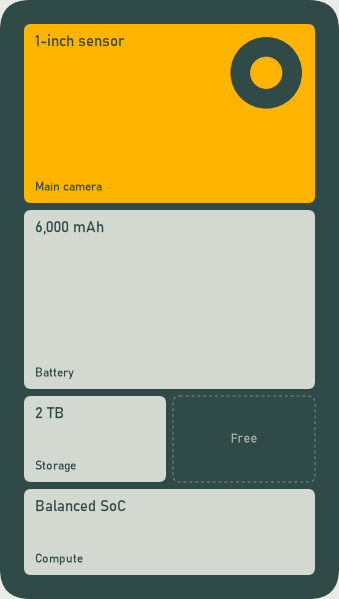
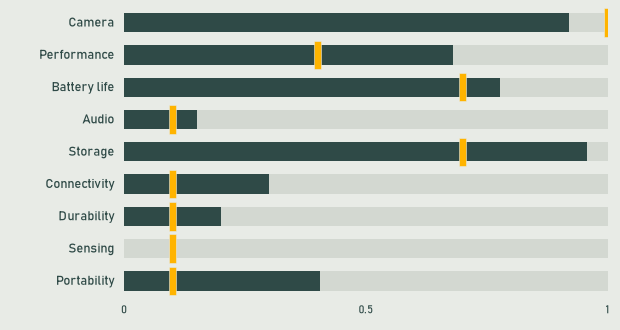

Module,Type,Price,Placement
50 MP standard camera,Main camera,"₹2,500","Top of the frame, clear of the grip"
"8,000 mAh pack",Battery,"₹5,000","Near the centre, for balance"
Efficiency SoC,Compute,"₹6,000",Away from the battery
Rugged armour spine,Protection,"₹3,500",Any free slot
Satellite + long-range radio,Connectivity,"₹5,500","Top or bottom edge, the antenna window"

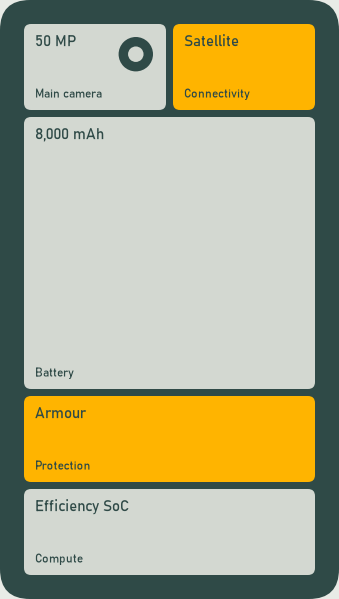
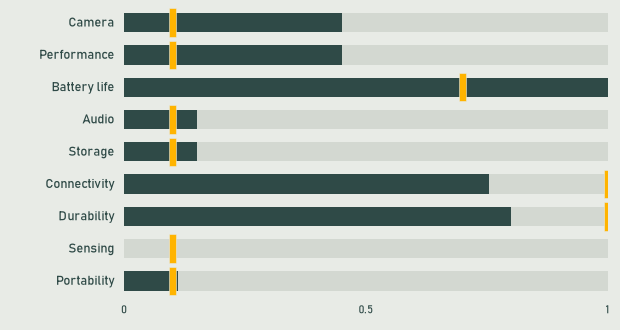

Module,Type,Price,Placement
50 MP standard camera,Main camera,"₹2,500","Top of the frame, clear of the grip"
"8,000 mAh pack",Battery,"₹5,000","Near the centre, for balance"
Flagship SoC,Compute,"₹22,000",Away from the battery
Stereo speaker module,Audio,"₹2,000","Bottom edge, facing out"
512 GB storage,Storage,"₹3,000",Any free slot
Vapour chamber,Cooling,"₹2,500",Touching the SoC

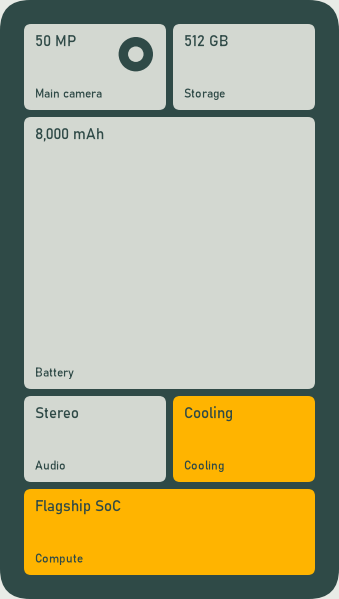
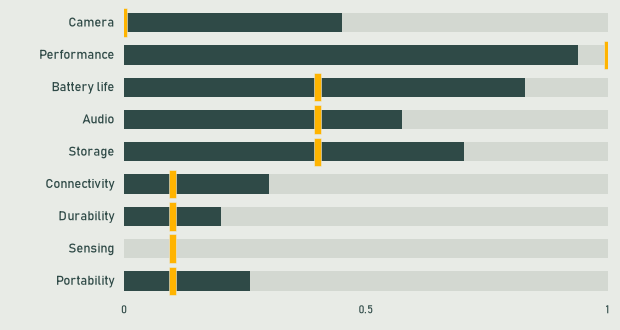

In [14]:
examples = presets()
for name in ("Wedding photographer", "Trek guide", "Hinglish gamer"):
    show_request(examples[name]["text"], examples[name])


Without Claude, a typed request goes to keyword matching. The first request below uses words on the list and gets a sensible build. The second uses none, and the result says so.

Module,Type,Price,Placement
1-inch pro sensor,Main camera,"₹14,000","Top of the frame, clear of the grip"
Balanced SoC,Compute,"₹11,000",Away from the battery
"3,000 mAh pack",Battery,"₹1,800","Near the centre, for balance"
Hi-Fi DAC + speakers,Audio,"₹6,500","Bottom edge, facing out"
2 TB storage,Storage,"₹9,500",Any free slot
Vapour chamber,Cooling,"₹2,500",Touching the SoC

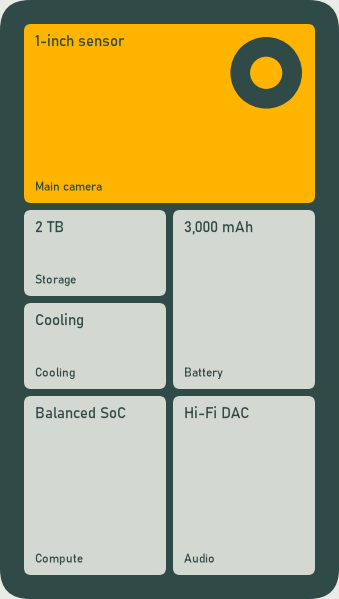
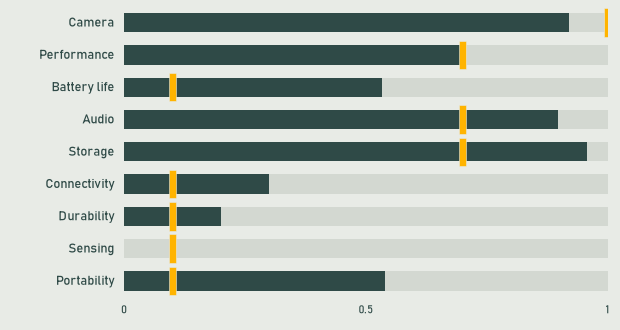

Module,Type,Price,Placement
108 MP wide camera,Main camera,"₹6,500","Top of the frame, clear of the grip"
Balanced SoC,Compute,"₹11,000",Away from the battery
"3,000 mAh pack",Battery,"₹1,800","Near the centre, for balance"
Rugged armour spine,Protection,"₹3,500",Any free slot
Stereo speaker module,Audio,"₹2,000","Bottom edge, facing out"
512 GB storage,Storage,"₹3,000",Any free slot
mmWave 5G + Wi-Fi 7,Connectivity,"₹5,000","Top or bottom edge, the antenna window"
"ECG, SpO2 + temperature",Sensors,"₹4,500","Mid-frame, under the index finger"

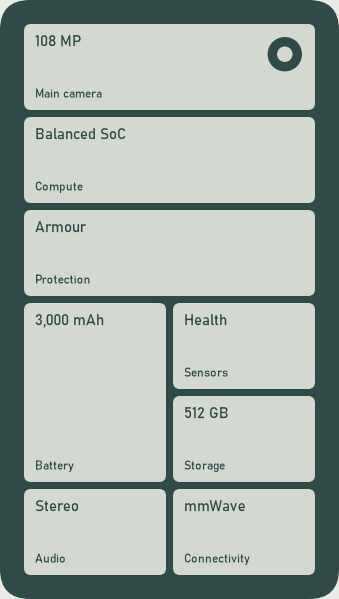
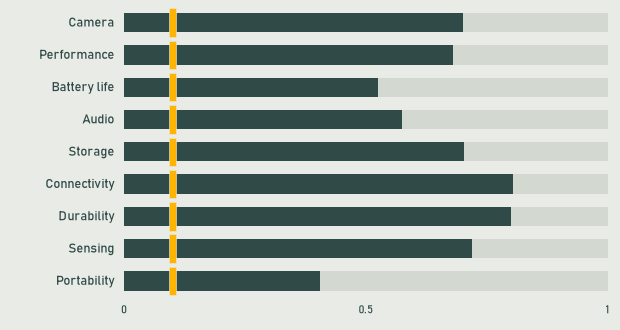

In [15]:
show_request("I shoot videos for YouTube and edit on the phone, need lots of storage, around 60k.")
show_request("I fix wind turbines and climb towers in storms.")


## 11. Try it

Run this cell, then pick an example or type a request and click *Build my phone*. Open *Change the priorities* to adjust the sliders by hand.

In [ ]:
TYPE_OWN = "Type my own"
examples = presets()
first = next(iter(examples.values()))

prompt_box = widgets.Textarea(value=first["text"], layout=widgets.Layout(width="100%", height="90px"))
example_picker = widgets.Dropdown(options=[TYPE_OWN, *examples], value=first["name"], description="Examples")
build_button = widgets.Button(description="Build my phone", button_style="primary")
option_picker = widgets.ToggleButtons(options=["Best", "Second", "Third"])
sliders = {d: widgets.FloatSlider(value=0.1, min=0, max=1, step=0.05, description=DIM_LABELS[d],
                                  continuous_update=False) for d in DIMS}
budget_box = widgets.BoundedIntText(value=0, min=0, max=500000, step=1000, description="Budget ₹")
must_box = widgets.SelectMultiple(options=[(m.name, m.id) for m in MODULES], description="Must have", rows=6)
view = widgets.Output()
ui = {"updating": False, "html": ""}


def refresh(_=None):
    if ui["updating"]:
        return
    need = {d: sliders[d].value for d in DIMS}
    edited = any(abs(need[d] - ui["parsed_needs"][d]) > 1e-6 for d in DIMS)
    status = "Priorities changed by hand." if edited else SOURCE_TEXT[ui["source"]]
    ui["html"] = build_card(ui["text"], need, budget_box.value or None, tuple(must_box.value),
                            ["Best", "Second", "Third"].index(option_picker.value), status, ui["raw"], ui["notice"])
    with view:
        view.clear_output(wait=True)
        display(HTML(ui["html"]))


def run_request(_=None):
    text = prompt_box.value.strip()
    if not text:
        return
    person = next((p for p in examples.values() if p["text"] == text), None)
    parsed, raw, source, notice = read_request(text, person)
    ui.update(updating=True, text=text, raw=raw, source=source, notice=notice, parsed_needs=dict(parsed.needs))
    for d in DIMS:
        sliders[d].value = parsed.needs[d]
    budget_box.value = parsed.budget or 0
    must_box.value = tuple(parsed.must_have)
    option_picker.value = "Best"
    example_picker.value = person["name"] if person else TYPE_OWN
    ui["updating"] = False
    refresh()


def pick_example(change):
    if not ui["updating"] and change["new"] != TYPE_OWN:
        prompt_box.value = examples[change["new"]]["text"]
        run_request()


example_picker.observe(pick_example, names="value")
build_button.on_click(run_request)
for control in (*sliders.values(), budget_box, must_box, option_picker):
    control.observe(refresh, names="value")

priorities = widgets.Accordion(children=[widgets.VBox([*sliders.values(), budget_box, must_box])], selected_index=None)
priorities.set_title(0, "Change the priorities")
display(widgets.VBox([prompt_box, widgets.HBox([example_picker, build_button]), priorities, option_picker, view]))
run_request()
